# Olist Brazilian E-Commerce Analysis

End-to-end analysis of the Olist Brazilian E-Commerce public dataset: data validation, a clean order-level master table, exploratory analysis of delivery, customers, revenue, products, sellers, and reviews, cohort retention, RFM segmentation, a statistical test with effect size, and a set of exported summary datasets.

## Contents

1. Setup
2. Data Loading
3. Data Quality Audit
4. Orders Preparation
5. Master Dataset
6. Exploratory Analysis
   - 6.1 Order Status
   - 6.2 Delivery Performance
   - 6.3 Customers
   - 6.4 Revenue and Payments
   - 6.5 Products and Categories
   - 6.6 Sellers
   - 6.7 Customer Reviews
7. KPI Summary and Business Insights
8. Export
9. Advanced Customer Analytics
   - 9.1 Analysis Population
   - 9.2 Cohort Retention
   - 9.3 RFM Segmentation
   - 9.4 Statistical Test and Effect Size
   - 9.5 Revenue and Payment Metric Definitions
10. Limitations and Interpretation
11. Final Business Recommendations
12. Export Advanced Analysis Tables
- Appendix A. Geolocation Cleaning

## 1. Setup

Imports, configuration, and reusable helper functions used throughout the notebook.

### 1.1 Imports and Display Settings

In [7]:
import os
import unicodedata
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.ticker import FuncFormatter
from IPython.display import display

pd.set_option('display.max_columns', None)

### 1.2 Configuration and Paths

All tunable parameters live here. The data directory is detected automatically: the default Kaggle location is tried first, then a recursive search of `/kaggle/input` and the current directory.

In [8]:
# Analysis parameters
MIN_CITY_SAMPLE = 100        # minimum orders or customers for a city to be ranked
MIN_MONTH_SAMPLE = 100       # minimum orders or reviews for a month to appear in trend charts
MIN_ITEMS_PER_SELLER = 20    # minimum items sold for a seller to be ranked by average price
TOP_N = 10                   # number of rows shown in rankings and charts
NEGATIVE_MAX_SCORE = 2       # review scores up to this value are treated as negative
BRAZIL_LAT_RANGE = (-34, 6)
BRAZIL_LNG_RANGE = (-74, -34)
MAJOR_CITIES = ['sao paulo', 'rio de janeiro', 'belo horizonte', 'brasilia', 'curitiba']

# Paths
REQUIRED_FILE = 'olist_customers_dataset.csv'
DEFAULT_DATA_DIR = Path('/kaggle/input/datasets/olistbr/brazilian-ecommerce')


def find_data_dir():
    """Locate the folder that contains the Olist CSV files."""
    if (DEFAULT_DATA_DIR / REQUIRED_FILE).exists():
        return DEFAULT_DATA_DIR
    for root in (Path('/kaggle/input'), Path('.')):
        matches = list(root.rglob(REQUIRED_FILE))
        if matches:
            return matches[0].parent
    raise FileNotFoundError(
        'Olist dataset not found. Add the Brazilian E-Commerce dataset to the notebook.'
    )


DATA_DIR = find_data_dir()
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('output')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print('Data directory  :', DATA_DIR)
print('Output directory:', OUTPUT_DIR)
print('Files found     :', sorted(os.listdir(DATA_DIR)))

Data directory  : .
Output directory: output
Files found     : ['brazilian-e-commerce.ipynb', 'brazilian-e-commerce_EDA.ipynb', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'output', 'product_category_name_translation.csv']


### 1.3 Helper Functions and Chart Style

Text normalization, coordinate validation, and plotting helpers. A single visual style (colors, spines, grid, thousands separators, value labels) is applied to every chart so the notebook looks consistent. `ACCENT` is used for problem metrics such as late deliveries and negative reviews.

In [9]:
def normalize_city(name):
    """Lowercase a city name and strip accents and surrounding whitespace."""
    if not isinstance(name, str):
        return name
    decomposed = unicodedata.normalize('NFKD', name)
    without_accents = ''.join(c for c in decomposed if not unicodedata.combining(c))
    return without_accents.lower().strip()


def normalize_series(series):
    """Normalize city names once per unique value (much faster on large columns)."""
    mapping = {value: normalize_city(value) for value in series.dropna().unique()}
    return series.map(mapping)


def safe_mode(series):
    """Most frequent value of a Series, or NaN if the Series is empty."""
    mode = series.mode()
    return mode.iloc[0] if not mode.empty else np.nan


def within_brazil(df, lat_col, lng_col):
    """Boolean mask for rows whose coordinates fall inside Brazil's bounding box."""
    return (
        df[lat_col].between(*BRAZIL_LAT_RANGE)
        & df[lng_col].between(*BRAZIL_LNG_RANGE)
    )


# Visual style
PRIMARY = '#2F5D8C'
ACCENT = '#D1495B'

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#444444',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': 11,
    'axes.labelcolor': '#333333',
    'axes.prop_cycle': cycler(color=[PRIMARY, ACCENT, '#EDAE49', '#66A182', '#8E6C8A', '#9AA5B1']),
    'xtick.color': '#333333',
    'ytick.color': '#333333',
    'grid.color': '#CCCCCC',
    'grid.alpha': 0.6,
    'font.size': 10,
})


def _format_value(value):
    """Bar label: thousands separators, decimals only when needed."""
    value = float(value)
    return f'{value:,.0f}' if value.is_integer() else f'{value:,.2f}'


def _use_thousands(axis, values):
    """Show thousands separators on an axis when values are large."""
    if len(values) and max(abs(float(v)) for v in values) >= 1000:
        axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))


def _finish(fig, ax, title, xlabel, ylabel):
    ax.set_title(title, loc='left')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_axisbelow(True)
    fig.tight_layout()
    plt.show()


def plot_barh_top(series, title, xlabel, ylabel, figsize=(11, 6),
                  max_label_len=None, vline=None, color=PRIMARY):
    """Horizontal bar chart for a ranked Series, largest value on top, with value labels."""
    labels = [str(label)[:max_label_len] for label in series.index][::-1]
    values = list(series.values)[::-1]
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.barh(labels, values, color=color)
    ax.bar_label(bars, labels=[_format_value(v) for v in values], padding=4, fontsize=9)
    if vline is not None:
        ax.axvline(vline, linestyle='--', color='#444444', linewidth=1)
    ax.margins(x=0.12)
    _use_thousands(ax.xaxis, values)
    ax.grid(axis='x')
    ax.grid(axis='y', visible=False)
    _finish(fig, ax, title, xlabel, ylabel)


def plot_bar(labels, values, title, xlabel, ylabel, figsize=(9, 5),
             ylim=None, rotation=0, color=PRIMARY):
    """Vertical bar chart with value labels. `color` can be one color or one per bar."""
    values = list(values)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar([str(label) for label in labels], values, color=color)
    ax.bar_label(bars, labels=[_format_value(v) for v in values], padding=3, fontsize=9)
    if ylim is not None:
        ax.set_ylim(*ylim)
    else:
        ax.margins(y=0.1)
    _use_thousands(ax.yaxis, values)
    ax.tick_params(axis='x', rotation=rotation)
    ax.grid(axis='y')
    ax.grid(axis='x', visible=False)
    _finish(fig, ax, title, xlabel, ylabel)


def plot_line(x, y, title, xlabel, ylabel, figsize=(13, 6), ylim=None,
              rotation=45, color=PRIMARY):
    """Line chart with markers."""
    y = list(y)
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot([str(value) for value in x], y, marker='o', color=color, linewidth=2)
    if ylim is not None:
        ax.set_ylim(*ylim)
    _use_thousands(ax.yaxis, y)
    ax.tick_params(axis='x', rotation=rotation)
    ax.grid(axis='y')
    _finish(fig, ax, title, xlabel, ylabel)


def plot_pie(values, labels, title, explode=None, colors=None, figsize=(7, 7)):
    """Pie chart with percentage labels."""
    fig, ax = plt.subplots(figsize=figsize)
    ax.pie(values, labels=labels, autopct='%1.1f%%', startangle=90, explode=explode,
           colors=colors, wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


## 2. Data Loading

All nine source tables are loaded once, up front. Every later section works from these DataFrames.

### 2.1 Load Source Tables

In [10]:
def load_csv(file_name):
    """Read one Olist CSV file from the data directory."""
    return pd.read_csv(DATA_DIR / file_name)


df_customers = load_csv('olist_customers_dataset.csv')
df_orders = load_csv('olist_orders_dataset.csv')
df_order_items = load_csv('olist_order_items_dataset.csv')
df_order_payments = load_csv('olist_order_payments_dataset.csv')
df_order_reviews = load_csv('olist_order_reviews_dataset.csv')
df_products = load_csv('olist_products_dataset.csv')
df_sellers = load_csv('olist_sellers_dataset.csv')
df_geolocation = load_csv('olist_geolocation_dataset.csv')
df_category_translation = load_csv('product_category_name_translation.csv')

tables = {
    'customers': df_customers,
    'orders': df_orders,
    'order_items': df_order_items,
    'order_payments': df_order_payments,
    'order_reviews': df_order_reviews,
    'products': df_products,
    'sellers': df_sellers,
    'geolocation': df_geolocation,
    'category_translation': df_category_translation,
}

pd.DataFrame(
    {name: {'rows': df.shape[0], 'columns': df.shape[1]} for name, df in tables.items()}
).T

,rows,columns
customers,99441,5
orders,99441,8
order_items,112650,7
order_payments,103886,5
order_reviews,99224,7
products,32951,9
sellers,3095,4
geolocation,1000163,5
category_translation,71,2


### 2.2 Preview Each Table

First three rows of every table, to confirm the schema looks as expected.

In [11]:
for name, df in tables.items():
    print(f'--- {name} ---')
    display(df.head(3))

--- customers ---


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


--- orders ---


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


--- order_items ---


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


... (8 outputs left out)

--- geolocation ---


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP


--- category_translation ---


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


## 3. Data Quality Audit

Structural checks on every table before any transformation: duplicates, missing values, key uniqueness, referential integrity, and implausible values. Nothing is modified in this section.

### 3.1 Audit Summary

One row per table with its size, duplicate rows, and missing-value totals.

In [12]:
audit_summary = pd.DataFrame({
    name: {
        'rows': len(df),
        'columns': df.shape[1],
        'duplicate_rows': int(df.duplicated().sum()),
        'columns_with_missing': int((df.isna().sum() > 0).sum()),
        'total_missing_cells': int(df.isna().sum().sum()),
    }
    for name, df in tables.items()
}).T

audit_summary

,rows,columns,duplicate_rows,columns_with_missing,total_missing_cells
customers,99441,5,0,0,0
orders,99441,8,0,3,4908
order_items,112650,7,0,0,0
order_payments,103886,5,0,0,0
order_reviews,99224,7,0,2,145903
products,32951,9,0,8,2448
sellers,3095,4,0,0,0
geolocation,1000163,5,261831,0,0
category_translation,71,2,0,0,0


### 3.2 Missing Values by Column

Only columns that actually contain missing values are listed.

In [13]:
for name, df in tables.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]
    if missing.empty:
        continue
    print(f'--- {name} ---')
    display(pd.DataFrame({
        'missing_values': missing,
        'missing_pct': (missing / len(df) * 100).round(2),
    }))

--- orders ---


,missing_values,missing_pct
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98


--- order_reviews ---


,missing_values,missing_pct
review_comment_title,87656,88.34
review_comment_message,58247,58.70


--- products ---


,missing_values,missing_pct
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


### 3.3 Primary Key Uniqueness

Each of these columns should uniquely identify a row in its table.

In [14]:
key_columns = {
    'customers': (df_customers, 'customer_id'),
    'orders': (df_orders, 'order_id'),
    'products': (df_products, 'product_id'),
    'sellers': (df_sellers, 'seller_id'),
    'category_translation': (df_category_translation, 'product_category_name'),
}

pd.DataFrame({
    name: {
        'key': key,
        'rows': len(df),
        'unique_keys': df[key].nunique(),
        'duplicate_keys': int(df[key].duplicated().sum()),
    }
    for name, (df, key) in key_columns.items()
}).T

,key,rows,unique_keys,duplicate_keys
customers,customer_id,99441,99441,0
orders,order_id,99441,99441,0
products,product_id,32951,32951,0
sellers,seller_id,3095,3095,0
category_translation,product_category_name,71,71,0


### 3.4 Customer Identity: `customer_id` vs `customer_unique_id`

In Olist, `customer_id` is generated per order, while `customer_unique_id` identifies the real person. Repeat purchases therefore show up as one `customer_unique_id` linked to several `customer_id` values. All customer-level metrics in this notebook use `customer_unique_id`.

In [15]:
records_per_customer = df_customers['customer_unique_id'].value_counts()

print('Unique customer_id           :', df_customers['customer_id'].nunique())
print('Unique customer_unique_id    :', df_customers['customer_unique_id'].nunique())
print('Customers with multiple ids  :', int((records_per_customer > 1).sum()))
print('Max ids for a single customer:', records_per_customer.max())

Unique customer_id           : 99441
Unique customer_unique_id    : 96096
Customers with multiple ids  : 2997
Max ids for a single customer: 17


### 3.5 Referential Integrity

Counts of records that point to a missing parent record, plus orders that have no payment or no items. Orders without items are examined in detail later, in the master dataset section.

In [16]:
integrity_checks = pd.Series({
    'Orders without a customer record': (~df_orders['customer_id'].isin(df_customers['customer_id'])).sum(),
    'Customers without any order': (~df_customers['customer_id'].isin(df_orders['customer_id'])).sum(),
    'Order items without an order': (~df_order_items['order_id'].isin(df_orders['order_id'])).sum(),
    'Order items without a product': (~df_order_items['product_id'].isin(df_products['product_id'])).sum(),
    'Order items without a seller': (~df_order_items['seller_id'].isin(df_sellers['seller_id'])).sum(),
    'Payments without an order': (~df_order_payments['order_id'].isin(df_orders['order_id'])).sum(),
    'Reviews without an order': (~df_order_reviews['order_id'].isin(df_orders['order_id'])).sum(),
    'Orders without payment': (~df_orders['order_id'].isin(df_order_payments['order_id'])).sum(),
    'Orders without items': (~df_orders['order_id'].isin(df_order_items['order_id'])).sum(),
}, name='count').to_frame()

integrity_checks

,count
Orders without a customer record,0
Customers without any order,0
Order items without an order,0
Order items without a product,0
Order items without a seller,0
Payments without an order,0
Reviews without an order,0
Orders without payment,1
Orders without items,775


### 3.6 Value Checks: Order Items and Products

Looks for duplicated rows and implausible prices, freight values, weights, and missing categories.

In [17]:
value_checks = pd.Series({
    'Order items: duplicate rows': df_order_items.duplicated().sum(),
    'Order items: zero price': (df_order_items['price'] == 0).sum(),
    'Order items: negative price': (df_order_items['price'] < 0).sum(),
    'Order items: zero freight': (df_order_items['freight_value'] == 0).sum(),
    'Order items: negative freight': (df_order_items['freight_value'] < 0).sum(),
    'Products: missing category': df_products['product_category_name'].isna().sum(),
    'Products: zero weight': (df_products['product_weight_g'] == 0).sum(),
}, name='count').to_frame()

display(value_checks)
display(df_order_items[['price', 'freight_value']].describe())

,count
Order items: duplicate rows,0
Order items: zero price,0
Order items: negative price,0
Order items: zero freight,383
Order items: negative freight,0
Products: missing category,610
Products: zero weight,4


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


**Audit takeaways.** The data is clean enough to analyze, with a few known gaps that are handled explicitly later:

- 775 orders have no items: 603 are `unavailable`, 164 are `canceled`, and 8 have another status.
- 8 orders are marked `delivered` but have no delivery date, and 1 order has no payment record.
- 610 products have no category, and 383 order items have zero freight.
- The raw geolocation table contains 261,831 duplicate rows (26%); it is cleaned in Appendix A.

## 4. Orders Preparation

Converts order timestamps to datetime and derives the delivery metrics used by the rest of the analysis. This is done once, here, so no later section needs to re-parse dates.

### 4.1 Parse Date Columns

Invalid or missing timestamps become `NaT` instead of raising an error.

In [18]:
ORDER_DATE_COLUMNS = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]

for column in ORDER_DATE_COLUMNS:
    df_orders[column] = pd.to_datetime(df_orders[column], errors='coerce')

df_orders[ORDER_DATE_COLUMNS].dtypes.to_frame('dtype')

,dtype
order_purchase_timestamp,datetime64[us]
order_approved_at,datetime64[us]
order_delivered_carrier_date,datetime64[us]
order_delivered_customer_date,datetime64[us]
order_estimated_delivery_date,datetime64[us]


### 4.2 Derive Delivery Metrics

- `purchase_month`: month of purchase, used for monthly trends.
- `delivery_days`: days from purchase to actual delivery to the customer.
- `delivery_difference`: days between actual and estimated delivery. Positive values mean the order arrived later than estimated.

Both delivery metrics are `NaN` for orders that were never delivered.

In [19]:
ONE_DAY = pd.Timedelta(days=1)

df_orders['purchase_month'] = df_orders['order_purchase_timestamp'].dt.to_period('M')

df_orders['delivery_days'] = (
    df_orders['order_delivered_customer_date'] - df_orders['order_purchase_timestamp']
) / ONE_DAY

df_orders['delivery_difference'] = (
    df_orders['order_delivered_customer_date'] - df_orders['order_estimated_delivery_date']
) / ONE_DAY

df_orders[[
    'order_purchase_timestamp', 'order_delivered_customer_date',
    'order_estimated_delivery_date', 'delivery_days', 'delivery_difference',
]].head(10)

,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delivery_difference
0,2017-10-02 10:56:33,2017-10-10 21:25:13,2017-10-18,8.436574,-7.107488
1,2018-07-24 20:41:37,2018-08-07 15:27:45,2018-08-13,13.782037,-5.355729
2,2018-08-08 08:38:49,2018-08-17 18:06:29,2018-09-04,9.394213,-17.245498
3,2017-11-18 19:28:06,2017-12-02 00:28:42,2017-12-15,13.208750,-12.980069
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2018-02-26,2.873877,-9.238171
5,2017-07-09 21:57:05,2017-07-26 10:57:55,2017-08-01,16.542245,-5.543113
6,2017-04-11 12:22:08,NaT,2017-05-09,NaN,NaN
7,2017-05-16 13:10:30,2017-05-26 12:55:51,2017-06-07,9.989826,-11.461215
8,2017-01-23 18:29:09,2017-02-02 14:08:10,2017-03-06,9.818762,-31.410995
9,2017-07-29 11:55:02,2017-08-16 17:14:30,2017-08-23,18.221852,-6.281597


### 4.3 Delivered Orders With Missing Dates

A small number of orders have status `delivered` but no delivery date. They cannot be used for delivery-time analysis and are excluded later from the delivered subset.

In [20]:
is_delivered = df_orders['order_status'].eq('delivered')
delivered_without_date = is_delivered & df_orders['delivery_days'].isna()

print('Orders with status delivered                 :', is_delivered.sum())
print('Delivered with missing delivery date         :', delivered_without_date.sum())
print('Delivered with a usable delivery date        :', (is_delivered & ~df_orders['delivery_days'].isna()).sum())

display(
    df_orders.loc[is_delivered, ['order_delivered_carrier_date', 'order_delivered_customer_date']]
    .isna().sum().to_frame('missing_values')
)
df_orders.loc[delivered_without_date, ['order_id', 'order_status'] + ORDER_DATE_COLUMNS]

Orders with status delivered                 : 96478
Delivered with missing delivery date         : 8
Delivered with a usable delivery date        : 96470


,missing_values
order_delivered_carrier_date,2
order_delivered_customer_date,8


,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


## 5. Master Dataset

Builds one row per order by joining orders with aggregated payments, customers, and aggregated order items. Payments and items are aggregated to one row per order **before** joining, which keeps every join one-to-one and prevents row duplication.

### 5.1 Aggregate Payments per Order

An order can be paid with several payment records (for example voucher plus credit card), so payment values are summed per order.

In [21]:
payments_summary = (
    df_order_payments
    .groupby('order_id')
    .agg(
        total_payment=('payment_value', 'sum'),
        payment_count=('payment_value', 'count'),
    )
    .reset_index()
)

print('Payment rows     :', len(df_order_payments))
print('Orders with payments:', len(payments_summary))
print('Duplicate orders :', payments_summary['order_id'].duplicated().sum())

payments_summary.head()

Payment rows     : 103886
Orders with payments: 99440
Duplicate orders : 0


,order_id,total_payment,payment_count
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,1
1,00018f77f2f0320c557190d7a144bdd3,259.83,1
2,000229ec398224ef6ca0657da4fc703e,216.87,1
3,00024acbcdf0a6daa1e931b038114c75,25.78,1
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,1


### 5.2 Aggregate Order Items per Order

In [22]:
items_summary = (
    df_order_items
    .groupby('order_id')
    .agg(
        total_items=('order_item_id', 'count'),
        total_product_price=('price', 'sum'),
        total_freight=('freight_value', 'sum'),
    )
    .reset_index()
)

print('Item rows        :', len(df_order_items))
print('Orders with items:', len(items_summary))
print('Duplicate orders :', items_summary['order_id'].duplicated().sum())

items_summary.head()

Item rows        : 112650
Orders with items: 98666
Duplicate orders : 0


,order_id,total_items,total_product_price,total_freight
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


### 5.3 Build `df_master`

The assertions confirm that the joins did not change the number of orders.

In [23]:
df_master = (
    df_orders
    .merge(payments_summary, on='order_id', how='left')
    .merge(df_customers, on='customer_id', how='left')
    .merge(items_summary, on='order_id', how='left')
)

assert len(df_master) == len(df_orders)
assert df_master['order_id'].is_unique

print('Orders in df_orders:', len(df_orders))
print('Rows in df_master  :', len(df_master))
print('Unique orders      :', df_master['order_id'].nunique())
print('Unique customers   :', df_master['customer_unique_id'].nunique())
print('Duplicate rows     :', df_master.duplicated().sum())

Orders in df_orders: 99441
Rows in df_master  : 99441
Unique orders      : 99441
Unique customers   : 96096
Duplicate rows     : 0


### 5.4 Master Dataset: Missing Values

In [24]:
missing_summary = (
    df_master.isna().sum()
    .rename('missing_values')
    .to_frame()
    .assign(missing_pct=lambda d: (d['missing_values'] / len(df_master) * 100).round(2))
)

missing_summary[missing_summary['missing_values'] > 0].sort_values('missing_values', ascending=False)

,missing_values,missing_pct
delivery_days,2965,2.98
order_delivered_customer_date,2965,2.98
delivery_difference,2965,2.98
order_delivered_carrier_date,1783,1.79
total_freight,775,0.78
total_items,775,0.78
total_product_price,775,0.78
order_approved_at,160,0.16
total_payment,1,0.00
payment_count,1,0.00


### 5.5 Orders Without Items

Orders that never reached the item stage are expected to be `unavailable` or `canceled`. Any other status listed below is a genuine data gap worth knowing about.

In [25]:
orders_without_items = df_master[df_master['total_items'].isna()]

print('Orders without items:', len(orders_without_items))

display(orders_without_items['order_status'].value_counts().to_frame('orders'))

orders_without_items.loc[
    ~orders_without_items['order_status'].isin(['unavailable', 'canceled']),
    ['order_id', 'order_status', 'order_purchase_timestamp'],
]

Orders without items: 775


,orders
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


,order_id,order_status,order_purchase_timestamp
7434,b5359909123fa03c50bdb0cfed07f098,created,2017-12-05 01:07:52
9238,dba5062fbda3af4fb6c33b1e040ca38f,created,2018-02-09 17:21:04
21441,7a4df5d8cff4090e541401a20a22bb80,created,2017-11-25 11:10:33
23254,a68ce1686d536ca72bd2dadc4b8671e5,shipped,2016-10-05 01:47:40
55086,35de4050331c6c644cddc86f4f2d0d64,created,2017-12-05 01:07:58
57591,2ce9683175cdab7d1c95bcbb3e36f478,invoiced,2016-10-05 21:03:33
58958,90ab3e7d52544ec7bc3363c82689965f,created,2017-11-06 13:12:34
69926,e04f1da1f48bf2bbffcf57b9824f76e1,invoiced,2016-10-05 13:22:20


### 5.6 Orders Without Payment

In [26]:
orders_without_payment = df_master[df_master['total_payment'].isna()]

print('Orders without payment:', len(orders_without_payment))

orders_without_payment[['order_id', 'order_status', 'total_payment', 'payment_count']]

Orders without payment: 1


,order_id,order_status,total_payment,payment_count
30710,bfbd0f9bdef84302105ad712db648a6c,delivered,NaN,NaN


### 5.7 Delivered Orders Subset

`df_delivered` contains orders with status `delivered` and a valid delivery date. Two columns are added:

- `is_late`: the order arrived after the estimated delivery date.
- `delivery_status`: `Late` or `On Time`, derived from `is_late`.

This subset is computed from `df_master`, so it already carries customer city and state.

In [27]:
df_delivered = df_master[
    (df_master['order_status'] == 'delivered') & df_master['delivery_days'].notna()
].copy()

df_delivered['is_late'] = df_delivered['delivery_difference'] > 0
df_delivered['delivery_status'] = np.where(df_delivered['is_late'], 'Late', 'On Time')

print('Delivered orders analyzed:', len(df_delivered))

df_delivered['delivery_days'].describe().to_frame('delivery_days')

Delivered orders analyzed: 96470


,delivery_days
count,96470.000000
mean,12.558217
std,9.546156
min,0.533414
25%,6.766204
50%,10.217477
75%,15.720182
max,209.628611


## 6. Exploratory Analysis

Each subsection answers one business question and is built on `df_master` (one row per order) or `df_delivered` unless stated otherwise.

### 6.1 Order Status

How are orders distributed across fulfillment statuses?

In [28]:
status_distribution = df_master['order_status'].value_counts().rename_axis('order_status').to_frame('orders')
status_distribution['percentage'] = (
    status_distribution['orders'] / status_distribution['orders'].sum() * 100
).round(2)

status_distribution

,orders,percentage
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Share of orders by status:

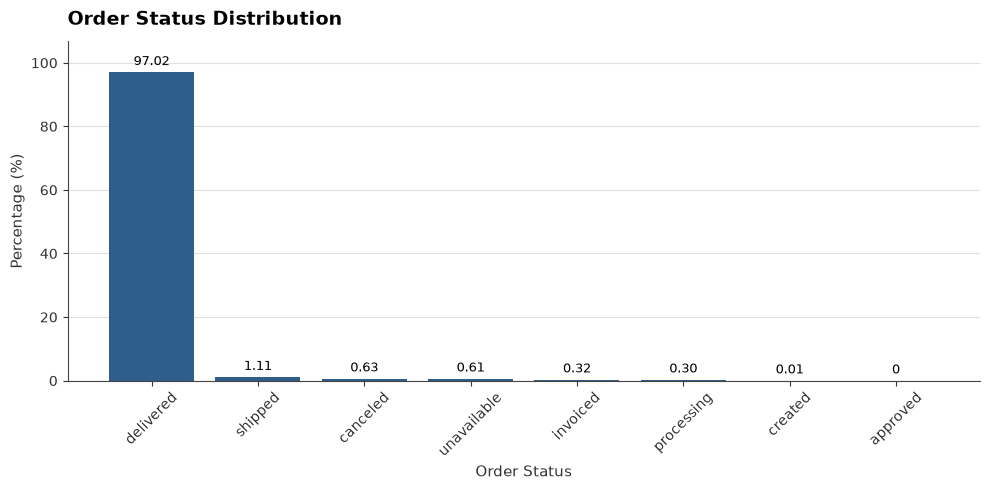

In [29]:
plot_bar(
    status_distribution.index, status_distribution['percentage'],
    'Order Status Distribution', 'Order Status', 'Percentage (%)',
    figsize=(10, 5), rotation=45,
)

**Takeaway.** 97.0% of orders reach the `delivered` status. Canceled (0.63%) and unavailable (0.61%) orders are each below 1%.

### 6.2 Delivery Performance

How long do deliveries take, and how often do they miss the estimated date?

#### 6.2.1 Overall On-Time vs Late Deliveries

,orders,percentage
delivery_status,,
On Time,88644,91.89
Late,7826,8.11


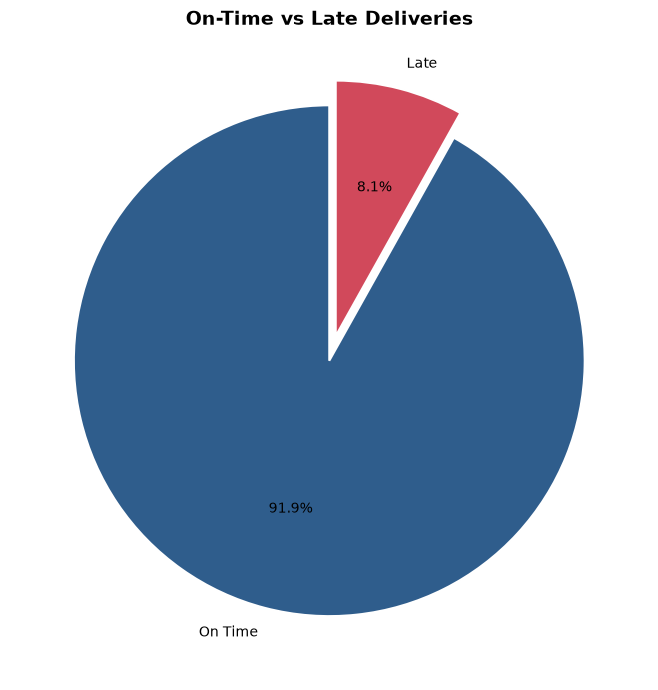

In [30]:
delivery_status_summary = df_delivered['delivery_status'].value_counts().to_frame('orders')
delivery_status_summary['percentage'] = (
    delivery_status_summary['orders'] / len(df_delivered) * 100
).round(2)

display(delivery_status_summary)

plot_pie(
    delivery_status_summary['orders'].values,
    delivery_status_summary.index,
    'On-Time vs Late Deliveries',
    explode=[0.1 if label == 'Late' else 0 for label in delivery_status_summary.index],
    colors=[ACCENT if label == 'Late' else PRIMARY for label in delivery_status_summary.index],
)

**Takeaway.** 91.9% of delivered orders arrive on or before the estimated date and 8.1% (7,826 orders) arrive late. The average delivery takes 12.6 days, the median is 10.2 days, and a long tail reaches 210 days.

#### 6.2.2 Monthly Delivery Trend

Average delivery time, order volume, and late-delivery rate by purchase month. Months with fewer than `MIN_MONTH_SAMPLE` orders stay in the table but are left out of the charts and rankings: the first months of the dataset have only a handful of orders, which makes their rates meaningless (a single late order would show as 100%).

In [31]:
monthly_delivery = (
    df_delivered
    .groupby('purchase_month')
    .agg(
        order_count=('order_id', 'count'),
        avg_delivery_days=('delivery_days', 'mean'),
        late_orders=('is_late', 'sum'),
    )
)
monthly_delivery['late_rate'] = monthly_delivery['late_orders'] / monthly_delivery['order_count'] * 100

monthly_delivery_ranked = monthly_delivery[monthly_delivery['order_count'] >= MIN_MONTH_SAMPLE]

monthly_delivery

,order_count,avg_delivery_days,late_orders,late_rate
purchase_month,,,,
2016-09,1,54.813194,1,100.000000
2016-10,265,19.600559,3,1.132075
2016-12,1,4.693021,0,0.000000
2017-01,750,12.647044,23,3.066667
2017-02,1653,13.168825,53,3.206292
2017-03,2546,12.951184,142,5.577376
2017-04,2303,14.917913,181,7.859314
2017-05,3545,11.322363,128,3.610719
2017-06,3135,12.011573,121,3.859649


Average delivery time by purchase month:

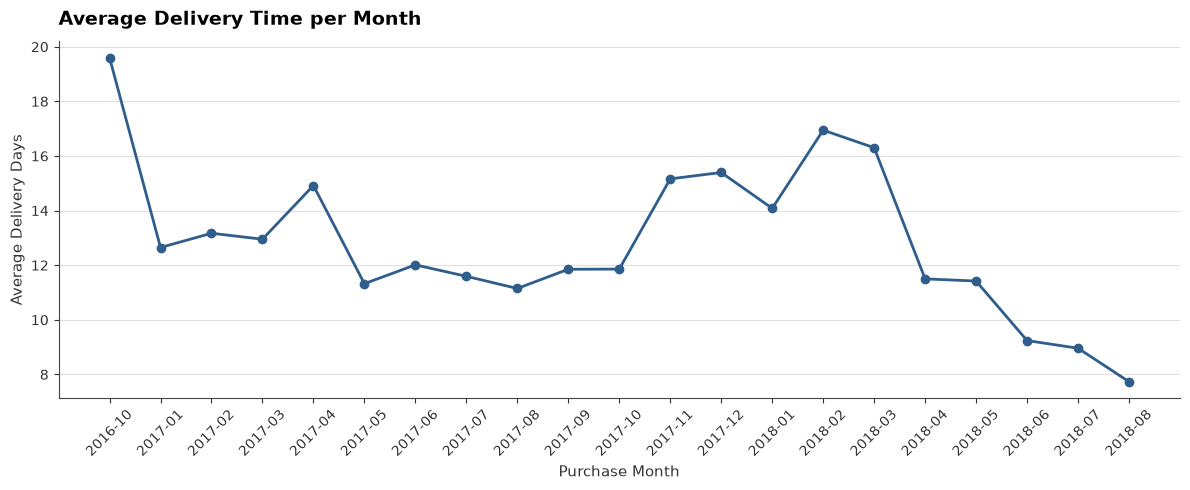

In [32]:
plot_line(
    monthly_delivery_ranked.index, monthly_delivery_ranked['avg_delivery_days'],
    'Average Delivery Time per Month', 'Purchase Month', 'Average Delivery Days',
    figsize=(12, 5),
)

Late-delivery rate by purchase month:

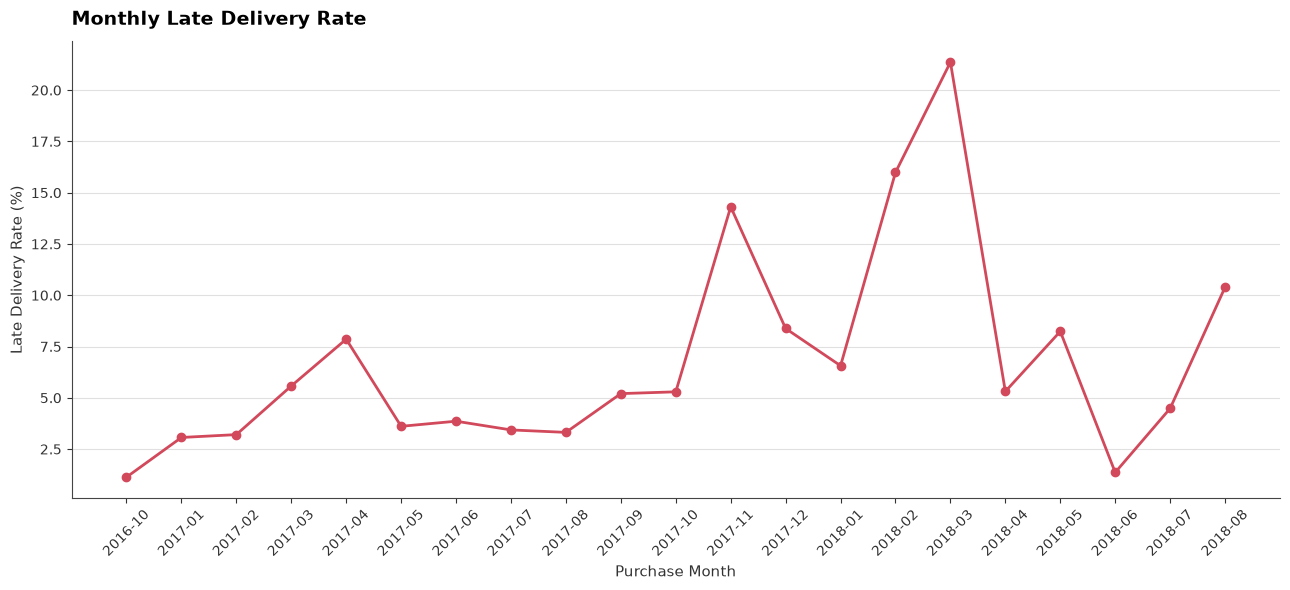

In [33]:
plot_line(
    monthly_delivery_ranked.index, monthly_delivery_ranked['late_rate'],
    'Monthly Late Delivery Rate', 'Purchase Month', 'Late Delivery Rate (%)',
    color=ACCENT,
)

Months with the highest late-delivery rate:

In [34]:
monthly_delivery_ranked.sort_values('late_rate', ascending=False).head(TOP_N)

,order_count,avg_delivery_days,late_orders,late_rate
purchase_month,,,,
2018-03,7003,16.301410,1496,21.362273
2018-02,6555,16.945138,1048,15.987796
2017-11,7288,15.161132,1043,14.311196
2018-08,6351,7.732780,660,10.392064
2017-12,5513,15.394919,462,8.380192
2018-05,6749,11.419029,556,8.238258
2017-04,2303,14.917913,181,7.859314
2018-01,7069,14.080563,464,6.563870
2017-03,2546,12.951184,142,5.577376


**Takeaway.** The late rate stays at roughly 1% to 8% in most months but spikes in November 2017 (14.3%) and in February and March 2018 (16.0% and 21.4%). The November 2017 spike coincides with a jump in order volume (7,288 orders against 4,478 in October). February and March 2018 had no comparable volume jump, so those delays point to a different cause.

#### 6.2.3 City-Level Delivery Metrics

One table holds every city-level delivery metric. Rankings only include cities with at least `MIN_CITY_SAMPLE` delivered orders.

In [35]:
city_delivery = (
    df_delivered
    .groupby('customer_city')
    .agg(
        total_orders=('order_id', 'nunique'),
        avg_delivery_days=('delivery_days', 'mean'),
        avg_delivery_difference=('delivery_difference', 'mean'),
        late_orders=('is_late', 'sum'),
    )
)
city_delivery['late_rate'] = city_delivery['late_orders'] / city_delivery['total_orders'] * 100

city_delivery_ranked = city_delivery[city_delivery['total_orders'] >= MIN_CITY_SAMPLE]

print('Cities in total      :', len(city_delivery))
print('Cities ranked (>= %d):' % MIN_CITY_SAMPLE, len(city_delivery_ranked))

city_delivery_ranked.nlargest(TOP_N, 'late_rate')

Cities in total      : 4085
Cities ranked (>= 100): 135


,total_orders,avg_delivery_days,avg_delivery_difference,late_orders,late_rate
customer_city,,,,,
maceio,236,25.701265,-5.828506,70,29.661017
sao goncalo,385,18.810620,-5.779190,96,24.935065
cabo frio,113,18.858586,-5.742311,27,23.893805
sao luis,335,20.498802,-7.933178,75,22.388060
teresina,271,20.922549,-7.860006,60,22.140221
sao joao de meriti,124,17.872392,-6.185875,27,21.774194
hortolandia,142,12.079485,-6.201209,30,21.126761
nova friburgo,142,19.643340,-5.211239,30,21.126761
rio das ostras,130,19.306193,-6.924989,27,20.769231


Chart of the cities with the highest late-delivery rate:

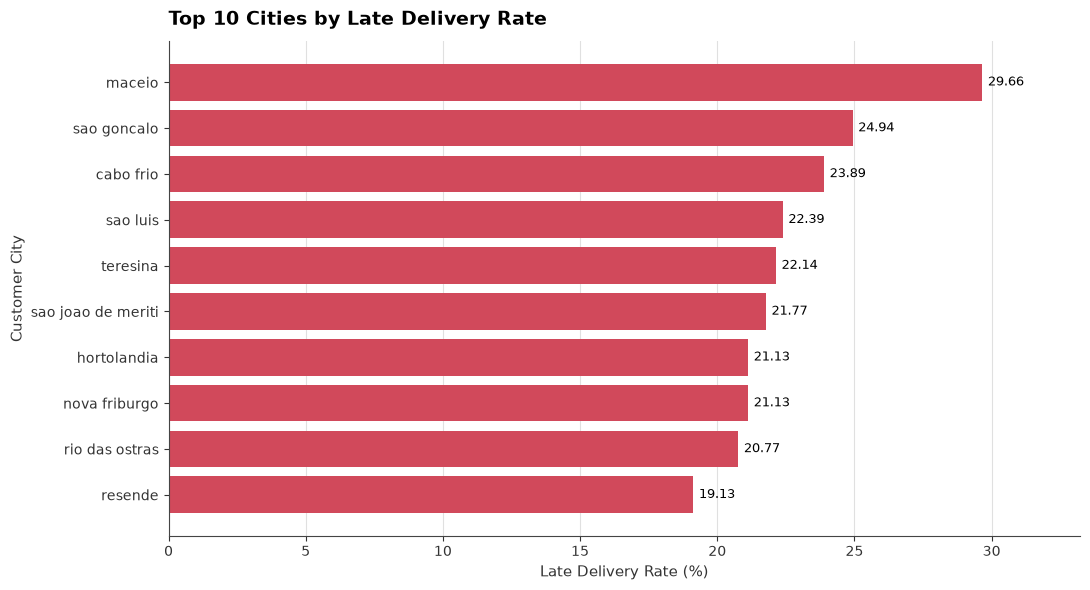

In [36]:
plot_barh_top(
    city_delivery_ranked.nlargest(TOP_N, 'late_rate')['late_rate'],
    'Top 10 Cities by Late Delivery Rate', 'Late Delivery Rate (%)', 'Customer City',
    color=ACCENT,
)

Cities with the longest average delivery time:

,total_orders,avg_delivery_days,avg_delivery_difference,late_orders,late_rate
customer_city,,,,,
manaus,137,26.464900,-18.225802,5,3.649635
maceio,236,25.701265,-5.828506,70,29.661017
belem,431,21.894802,-13.650560,42,9.744780
teresina,271,20.922549,-7.860006,60,22.140221
aracaju,213,20.711552,-9.524330,29,13.615023
fortaleza,618,20.629775,-8.995780,111,17.961165
sao luis,335,20.498802,-7.933178,75,22.388060
joao pessoa,245,20.479952,-11.388646,29,11.836735
nova friburgo,142,19.643340,-5.211239,30,21.126761


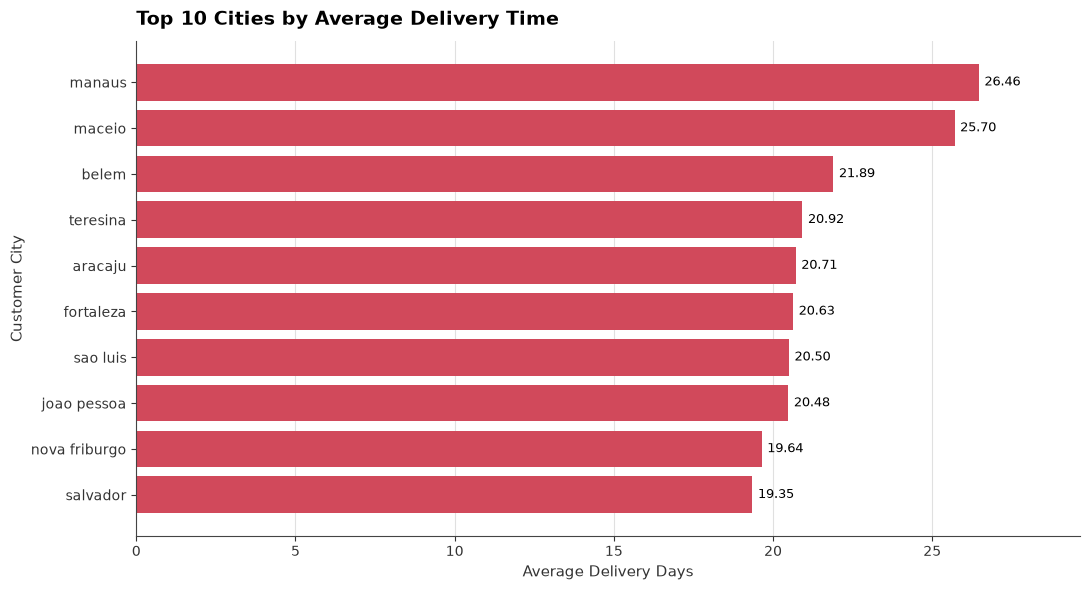

In [37]:
top_delivery_days = city_delivery_ranked.nlargest(TOP_N, 'avg_delivery_days')

display(top_delivery_days)

plot_barh_top(
    top_delivery_days['avg_delivery_days'],
    'Top 10 Cities by Average Delivery Time', 'Average Delivery Days', 'Customer City',
    color=ACCENT,
)

Average gap between actual and estimated delivery. Positive values mean orders arrive later than estimated on average; negative values mean earlier. In this dataset every ranked city averages earlier than its estimate, so the chart shows the cities with the smallest margin.

Cities that are late on average: 0


,avg_delivery_difference
count,135.000000
mean,-10.655566
std,2.123573
min,-18.225802
25%,-12.053706
50%,-10.609048
75%,-9.435461
max,-5.211239


,total_orders,avg_delivery_days,avg_delivery_difference,late_orders,late_rate
customer_city,,,,,
manaus,137,26.464900,-18.225802,5,3.649635
porto velho,108,19.191009,-17.882203,5,4.629630
gravatai,111,14.278747,-14.369573,3,2.702703
passo fundo,112,14.141212,-14.338410,5,4.464286
divinopolis,132,11.176623,-14.171881,2,1.515152
montes claros,207,11.086123,-13.709192,7,3.381643
belem,431,21.894802,-13.650560,42,9.744780
jaboatao dos guararapes,131,15.806885,-13.528191,8,6.106870
uberaba,186,11.175320,-13.356222,9,4.838710


,total_orders,avg_delivery_days,avg_delivery_difference,late_orders,late_rate
customer_city,,,,,
nova friburgo,142,19.643340,-5.211239,30,21.126761
cabo frio,113,18.858586,-5.742311,27,23.893805
sao goncalo,385,18.810620,-5.779190,96,24.935065
maceio,236,25.701265,-5.828506,70,29.661017
sao joao de meriti,124,17.872392,-6.185875,27,21.774194
hortolandia,142,12.079485,-6.201209,30,21.126761
sao vicente,159,11.213978,-6.850300,20,12.578616
rio das ostras,130,19.306193,-6.924989,27,20.769231
volta redonda,227,16.537902,-7.322602,41,18.061674


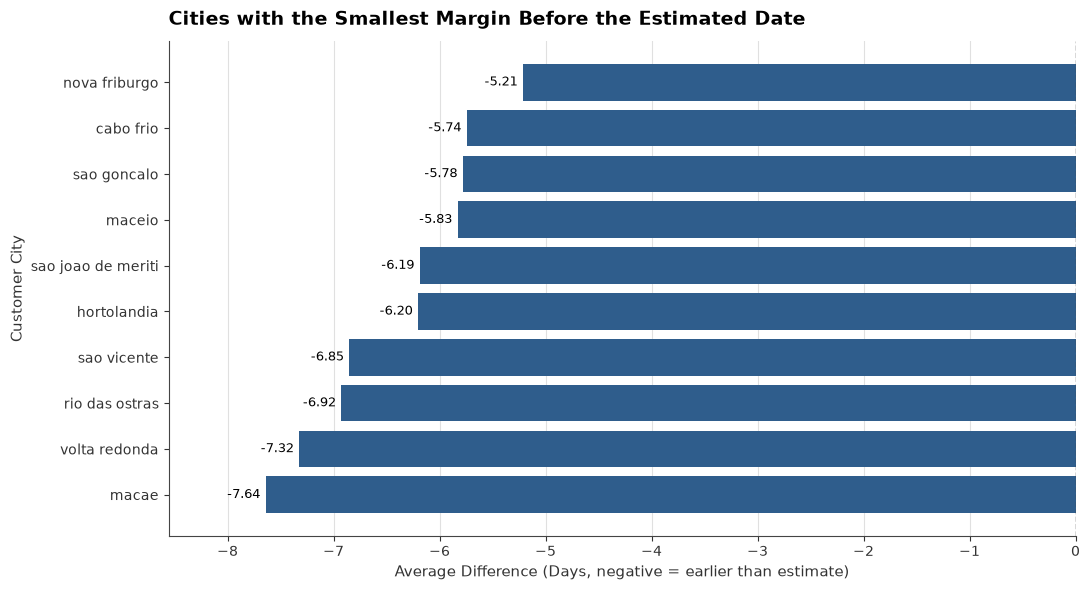

In [38]:
print('Cities that are late on average:', (city_delivery_ranked['avg_delivery_difference'] > 0).sum())

display(city_delivery_ranked['avg_delivery_difference'].describe().to_frame())
display(city_delivery_ranked.nsmallest(TOP_N, 'avg_delivery_difference'))

top_delivery_difference = city_delivery_ranked.nlargest(TOP_N, 'avg_delivery_difference')

display(top_delivery_difference)

plot_barh_top(
    top_delivery_difference['avg_delivery_difference'],
    'Cities with the Smallest Margin Before the Estimated Date',
    'Average Difference (Days, negative = earlier than estimate)', 'Customer City', vline=0,
)

**Takeaway.** Late rates are highest in Maceio (29.7%), Sao Goncalo (24.9%), and Cabo Frio (23.9%), while the slowest deliveries go to northern and northeastern cities such as Manaus (26.5 days) and Maceio (25.7 days). All 135 ranked cities average earlier than their estimate (between 5.2 and 18.2 days early), so the estimates are conservative and a long delivery time does not mean a late one: Manaus is the slowest city, yet only 3.6% of its orders are late.

### 6.3 Customers

Who are the customers, where are they, and how many come back?

#### 6.3.1 Orders and Spend per Customer

Customer-level table keyed on `customer_unique_id`. A customer is a repeat customer if they placed more than one order.

In [39]:
customer_orders = (
    df_master
    .groupby('customer_unique_id')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_spent=('total_payment', 'sum'),
    )
    .reset_index()
)
customer_orders['customer_type'] = np.where(
    customer_orders['total_orders'] > 1, 'Repeat Customer', 'One-Time Customer'
)

display(customer_orders.head(10))

customer_orders['total_orders'].value_counts().sort_index().rename_axis('orders_per_customer').to_frame('customers')

,customer_unique_id,total_orders,total_spent,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,86.22,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,One-Time Customer
5,0004bd2a26a76fe21f786e4fbd80607f,1,166.98,One-Time Customer
6,00050ab1314c0e55a6ca13cf7181fecf,1,35.38,One-Time Customer
7,00053a61a98854899e70ed204dd4bafe,1,419.18,One-Time Customer
8,0005e1862207bf6ccc02e4228effd9a0,1,150.12,One-Time Customer
9,0005ef4cd20d2893f0d9fbd94d3c0d97,1,129.76,One-Time Customer


,customers
orders_per_customer,
1,93099
2,2745
3,203
4,30
5,8
6,6
7,3
9,1
17,1


#### 6.3.2 Repeat Customer Rate

,Metric,Value
0,Total Customers,96096.00
1,One-Time Customers,93099.00
2,Repeat Customers,2997.00
3,Repeat Customer Rate,3.12


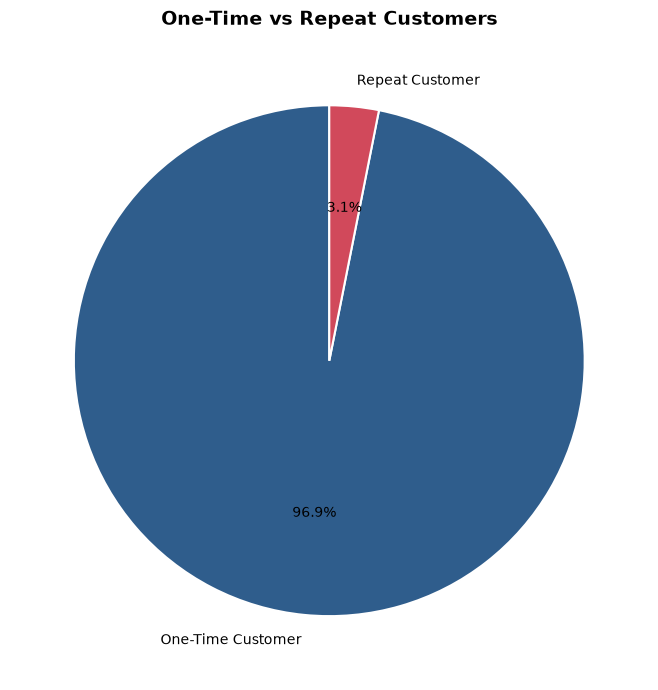

In [40]:
customer_type_counts = (
    customer_orders['customer_type']
    .value_counts()
    .reindex(['One-Time Customer', 'Repeat Customer'], fill_value=0)
)

total_customers = len(customer_orders)
one_time_customers = int(customer_type_counts['One-Time Customer'])
repeat_customers = int(customer_type_counts['Repeat Customer'])
repeat_customer_rate = repeat_customers / total_customers * 100

customer_summary = pd.DataFrame({
    'Metric': ['Total Customers', 'One-Time Customers', 'Repeat Customers', 'Repeat Customer Rate'],
    'Value': [total_customers, one_time_customers, repeat_customers, round(repeat_customer_rate, 2)],
})

display(customer_summary)

plot_pie(
    customer_type_counts.values, customer_type_counts.index,
    'One-Time vs Repeat Customers',
)

**Takeaway.** Only 3.1% of customers (2,997 of 96,096) placed a second order, which makes retention a clear opportunity.

#### 6.3.3 Customers by City

Counts use unique customers (`customer_unique_id`) rather than raw customer records, because one person can have several `customer_id` values.

,unique_customers,total_orders,customer_share_pct
customer_city,,,
sao paulo,14984,15540,15.59
rio de janeiro,6620,6882,6.89
belo horizonte,2672,2773,2.78
brasilia,2069,2131,2.15
curitiba,1465,1521,1.52
campinas,1398,1444,1.45
porto alegre,1326,1379,1.38
salvador,1209,1245,1.26
guarulhos,1153,1189,1.20


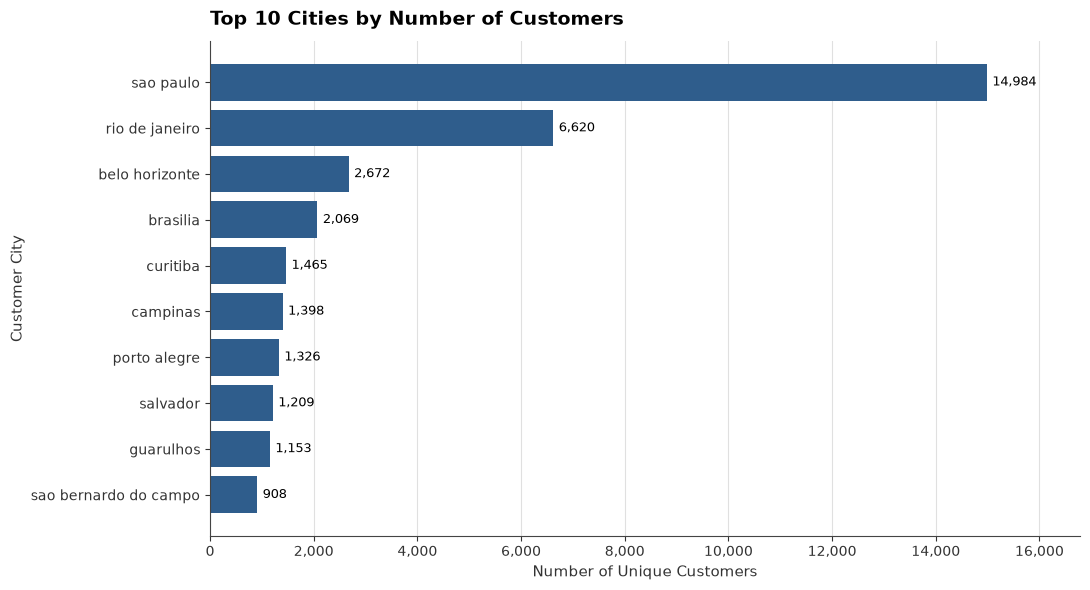

In [41]:
city_customers = (
    df_master
    .groupby('customer_city')
    .agg(
        unique_customers=('customer_unique_id', 'nunique'),
        total_orders=('order_id', 'nunique'),
    )
)
city_customers['customer_share_pct'] = (city_customers['unique_customers'] / total_customers * 100).round(2)

top_customer_cities = city_customers.nlargest(TOP_N, 'unique_customers')

display(top_customer_cities)

plot_barh_top(
    top_customer_cities['unique_customers'],
    'Top 10 Cities by Number of Customers', 'Number of Unique Customers', 'Customer City',
)

**Takeaway.** Customers are concentrated in a few metropolitan areas: Sao Paulo holds 15.6% of all unique customers and Rio de Janeiro 6.9%.

#### 6.3.4 Repeat Rate by City

Rankings only include cities with at least `MIN_CITY_SAMPLE` customers.

,total_customers,repeat_customers,repeat_rate
customer_city,,,
petropolis,220,14,6.363636
aparecida de goiania,104,6,5.769231
pouso alegre,124,7,5.645161
ponta grossa,135,7,5.185185
limeira,181,9,4.972376
nova friburgo,145,7,4.827586
franco da rocha,104,5,4.807692
porto velho,105,5,4.761905
mage,106,5,4.716981


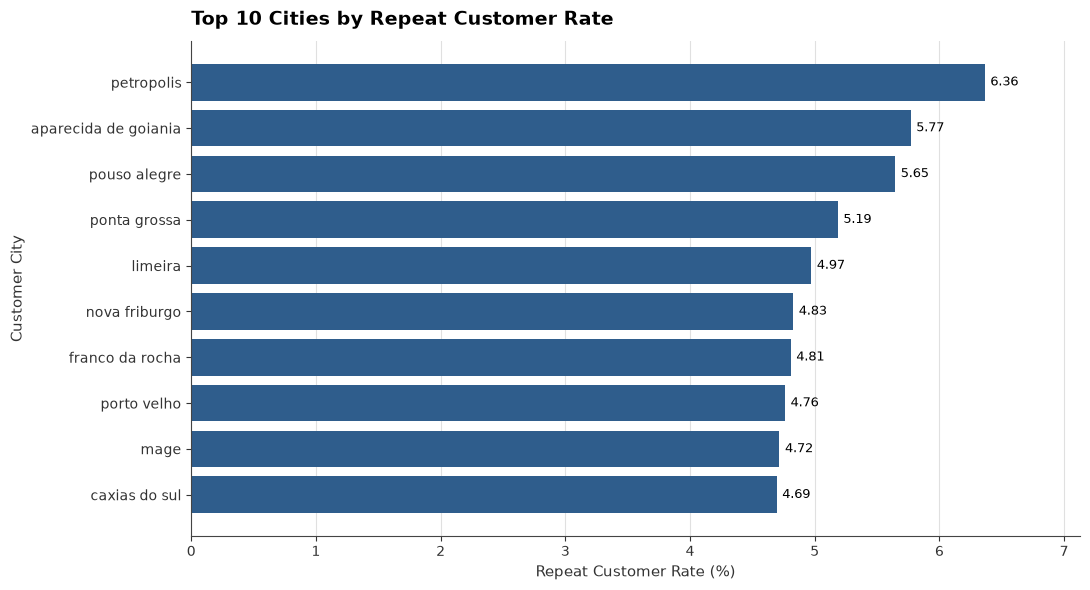

In [42]:
customer_city_orders = (
    df_master
    .groupby(['customer_city', 'customer_unique_id'])['order_id']
    .nunique()
    .reset_index(name='total_orders')
)

city_repeat = (
    customer_city_orders
    .groupby('customer_city')
    .agg(
        total_customers=('customer_unique_id', 'nunique'),
        repeat_customers=('total_orders', lambda orders: (orders > 1).sum()),
    )
)
city_repeat['repeat_rate'] = city_repeat['repeat_customers'] / city_repeat['total_customers'] * 100

top_repeat_cities = (
    city_repeat[city_repeat['total_customers'] >= MIN_CITY_SAMPLE]
    .nlargest(TOP_N, 'repeat_rate')
)

display(top_repeat_cities)

plot_barh_top(
    top_repeat_cities['repeat_rate'],
    'Top 10 Cities by Repeat Customer Rate', 'Repeat Customer Rate (%)', 'Customer City',
)

Repeat rate in the major cities, for comparison:

In [43]:
city_repeat.reindex(MAJOR_CITIES)

,total_customers,repeat_customers,repeat_rate
customer_city,,,
sao paulo,14984,502,3.350240
rio de janeiro,6620,236,3.564955
belo horizonte,2672,92,3.443114
brasilia,2069,60,2.899952
curitiba,1465,44,3.003413


**Takeaway.** Repeat rates are low everywhere. The five largest cities sit between 2.9% and 3.6%, and even the best city with 100 or more customers (Petropolis) reaches only 6.4%.

### 6.4 Revenue and Payments

Revenue here means the total payment value of an order, summed across all payment records. It includes every order status, so canceled and unavailable orders that still have payment records are included.

#### 6.4.1 Monthly Sales

In [44]:
monthly_sales = (
    df_master
    .groupby('purchase_month')
    .agg(
        total_sales=('total_payment', 'sum'),
        total_orders=('order_id', 'nunique'),
        average_order_value=('total_payment', 'mean'),
    )
    .reset_index()
    .rename(columns={'purchase_month': 'year_month'})
)
monthly_sales['year_month'] = monthly_sales['year_month'].astype(str)
monthly_sales = monthly_sales.sort_values('year_month')

monthly_sales.head(10)

,year_month,total_sales,total_orders,average_order_value
0,2016-09,252.24,4,84.080000
1,2016-10,59090.48,324,182.378025
2,2016-12,19.62,1,19.620000
3,2017-01,138488.04,800,173.110050
4,2017-02,291908.01,1780,163.993264
5,2017-03,449863.60,2682,167.734377
6,2017-04,417788.03,2404,173.788698
7,2017-05,592918.82,3700,160.248330
8,2017-06,511276.38,3245,157.558206
9,2017-07,592382.92,4026,147.139324


#### 6.4.2 Sales by City

Total sales, order count, and average order value (AOV) per customer city.

,customer_city,total_sales,total_orders,average_order_value
3597,sao paulo,2203373.09,15540,141.787200
3155,rio de janeiro,1161927.36,6882,168.835711
453,belo horizonte,421765.12,2773,152.097050
558,brasilia,354216.78,2131,166.220920
1143,curitiba,247392.48,1521,162.651203
2964,porto alegre,224731.42,1379,162.966947
3247,salvador,218071.50,1245,175.157831
707,campinas,216248.43,1444,149.756530
1529,guarulhos,165121.99,1189,138.874676
2461,niteroi,139996.99,849,164.896337


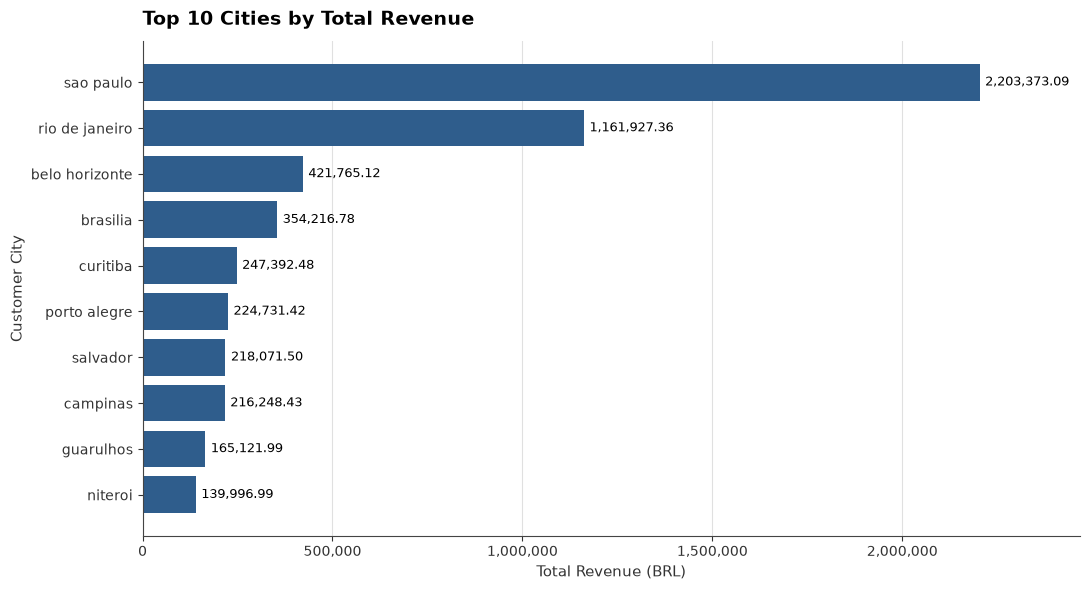

In [45]:
city_sales = (
    df_master
    .groupby('customer_city')
    .agg(
        total_sales=('total_payment', 'sum'),
        total_orders=('order_id', 'nunique'),
        average_order_value=('total_payment', 'mean'),
    )
    .reset_index()
    .sort_values('total_sales', ascending=False)
)

top_cities_revenue = city_sales.head(TOP_N)

display(top_cities_revenue)

plot_barh_top(
    top_cities_revenue.set_index('customer_city')['total_sales'],
    'Top 10 Cities by Total Revenue', 'Total Revenue (BRL)', 'Customer City',
)

Average order value by city, restricted to cities with at least `MIN_CITY_SAMPLE` orders:

,total_sales,total_orders,average_order_value
customer_city,,,
divinopolis,38970.08,137,284.453139
porto velho,29253.63,113,258.881681
joao pessoa,63353.63,256,247.475117
palmas,24281.20,110,220.738182
belem,96881.76,447,216.737718
teresina,60625.46,281,215.748968
maceio,53170.76,247,215.266235
natal,43606.49,207,210.659372
campo grande,67000.32,320,209.376000


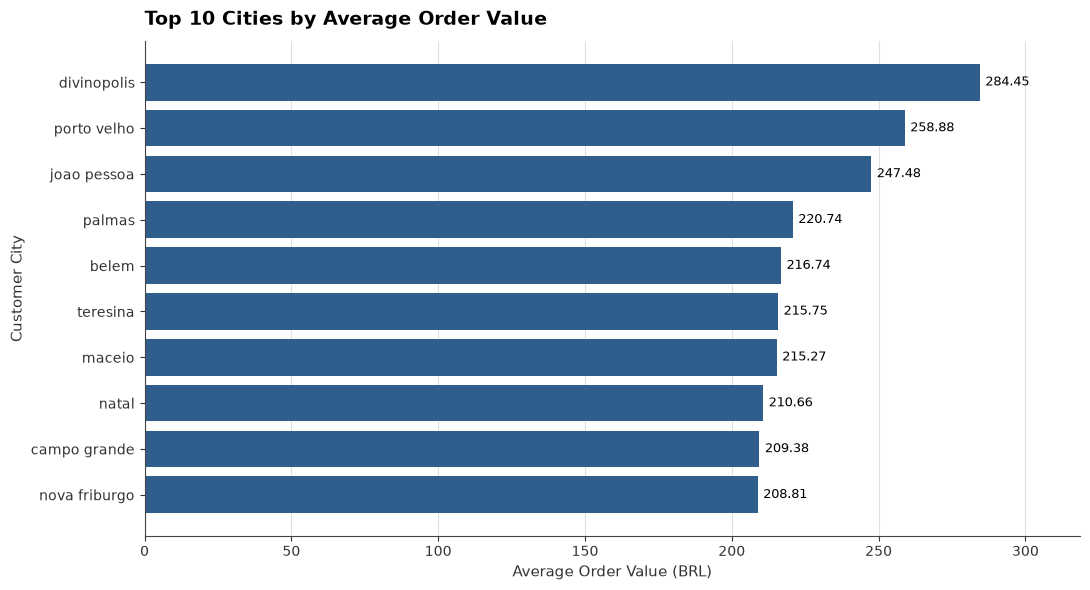

In [46]:
top_cities_aov = (
    city_sales[city_sales['total_orders'] >= MIN_CITY_SAMPLE]
    .nlargest(TOP_N, 'average_order_value')
    .set_index('customer_city')
)

display(top_cities_aov)

plot_barh_top(
    top_cities_aov['average_order_value'],
    'Top 10 Cities by Average Order Value', 'Average Order Value (BRL)', 'Customer City',
)

Sales metrics for the major cities, for comparison:

In [47]:
city_sales.set_index('customer_city').reindex(MAJOR_CITIES)

,total_sales,total_orders,average_order_value
customer_city,,,
sao paulo,2203373.09,15540,141.787200
rio de janeiro,1161927.36,6882,168.835711
belo horizonte,421765.12,2773,152.097050
brasilia,354216.78,2131,166.220920
curitiba,247392.48,1521,162.651203


**Takeaway.** Sao Paulo generates R$ 2.20M (13.8% of total payment value) and Rio de Janeiro R$ 1.16M (7.3%). Sao Paulo has the largest volume but a below-average order value (R$ 141.79 against R$ 160.99 overall), while Divinopolis (R$ 284) and Porto Velho (R$ 259) have the highest order values among cities with 100 or more orders.

#### 6.4.3 Payment Methods

In [48]:
payment_analysis = (
    df_order_payments
    .groupby('payment_type')
    .agg(
        total_transactions=('payment_value', 'count'),
        total_payment=('payment_value', 'sum'),
        avg_payment=('payment_value', 'mean'),
    )
    .sort_values('total_transactions', ascending=False)
)

payment_analysis

,total_transactions,total_payment,avg_payment
payment_type,,,
credit_card,76795,12542084.19,163.319021
boleto,19784,2869361.27,145.034435
voucher,5775,379436.87,65.703354
debit_card,1529,217989.79,142.570170
not_defined,3,0.00,0.000000


Total payment value and number of transactions by payment type:

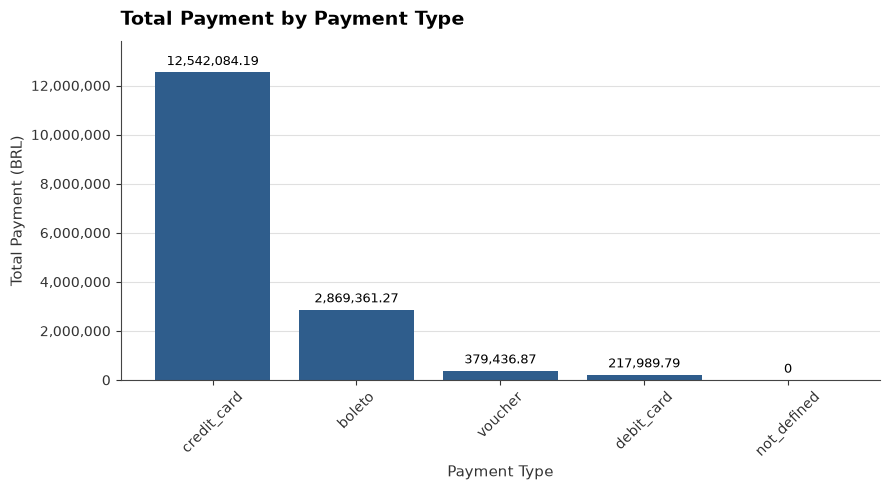

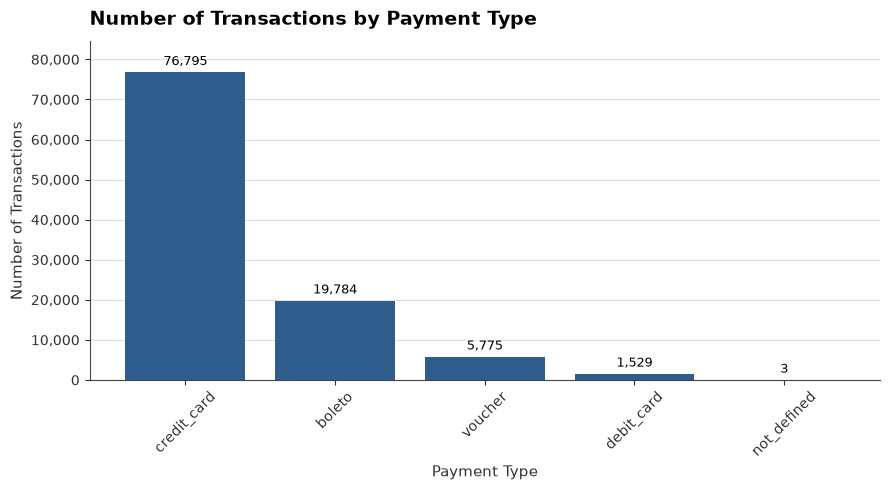

In [49]:
plot_bar(
    payment_analysis.index, payment_analysis['total_payment'],
    'Total Payment by Payment Type', 'Payment Type', 'Total Payment (BRL)',
    rotation=45,
)

plot_bar(
    payment_analysis.index, payment_analysis['total_transactions'],
    'Number of Transactions by Payment Type', 'Payment Type', 'Number of Transactions',
    rotation=45,
)

**Takeaway.** Credit cards account for 74% of transactions and 78% of payment value. Boleto is second (19% of transactions, 18% of value), and vouchers are small on average (R$ 66 against R$ 163 for credit cards).

### 6.5 Products and Categories

Which categories sell the most, earn the most, and carry the highest prices? Category names are translated to English using the translation table.

#### 6.5.1 Build the Item-Level Table

Order items joined with product attributes and English category names. Product-level left joins keep every item row; the assertion checks that.

In [50]:
df_items_analysis = (
    df_order_items
    .merge(df_products, on='product_id', how='left')
    .merge(df_category_translation, on='product_category_name', how='left')
)

assert len(df_items_analysis) == len(df_order_items)

print('Item rows                 :', len(df_items_analysis))
print('Unique products           :', df_items_analysis['product_id'].nunique())
print('Items without English name:', df_items_analysis['product_category_name_english'].isna().sum())

Item rows                 : 112650
Unique products           : 32951
Items without English name: 1627


#### 6.5.2 Category Summary

Items without an English category name are excluded from category rankings.

In [51]:
category_analysis = (
    df_items_analysis
    .groupby('product_category_name_english')
    .agg(
        total_items_sold=('order_item_id', 'count'),
        total_sales=('price', 'sum'),
        average_price=('price', 'mean'),
        unique_products=('product_id', 'nunique'),
        unique_orders=('order_id', 'nunique'),
    )
    .reset_index()
    .sort_values('total_sales', ascending=False)
)

category_analysis.head(TOP_N)

,product_category_name_english,total_items_sold,total_sales,average_price,unique_products,unique_orders
43,health_beauty,9670,1258681.34,130.163531,2444,8836
70,watches_gifts,5991,1205005.68,201.135984,1329,5624
7,bed_bath_table,11115,1036988.68,93.296327,3029,9417
65,sports_leisure,8641,988048.97,114.344285,2867,7720
15,computers_accessories,7827,911954.32,116.513903,1639,6689
39,furniture_decor,8334,729762.49,87.564494,2657,6449
20,cool_stuff,3796,635290.85,167.357969,789,3632
49,housewares,6964,632248.66,90.788148,2335,5884
5,auto,4235,592720.11,139.957523,1900,3897
42,garden_tools,4347,485256.46,111.630196,753,3518


Top 10 categories by items sold, revenue, and average price:

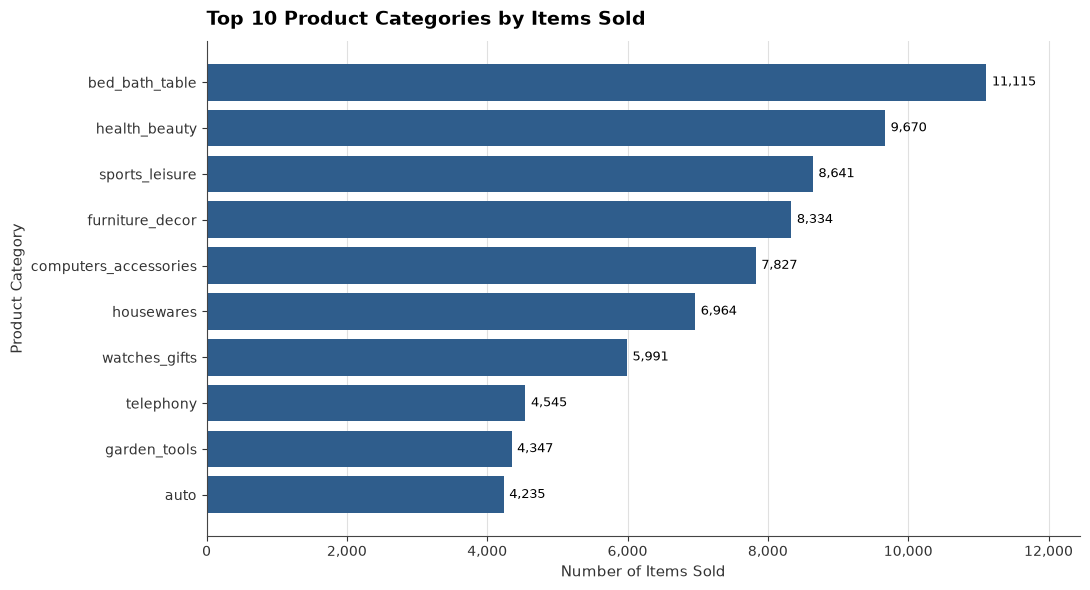

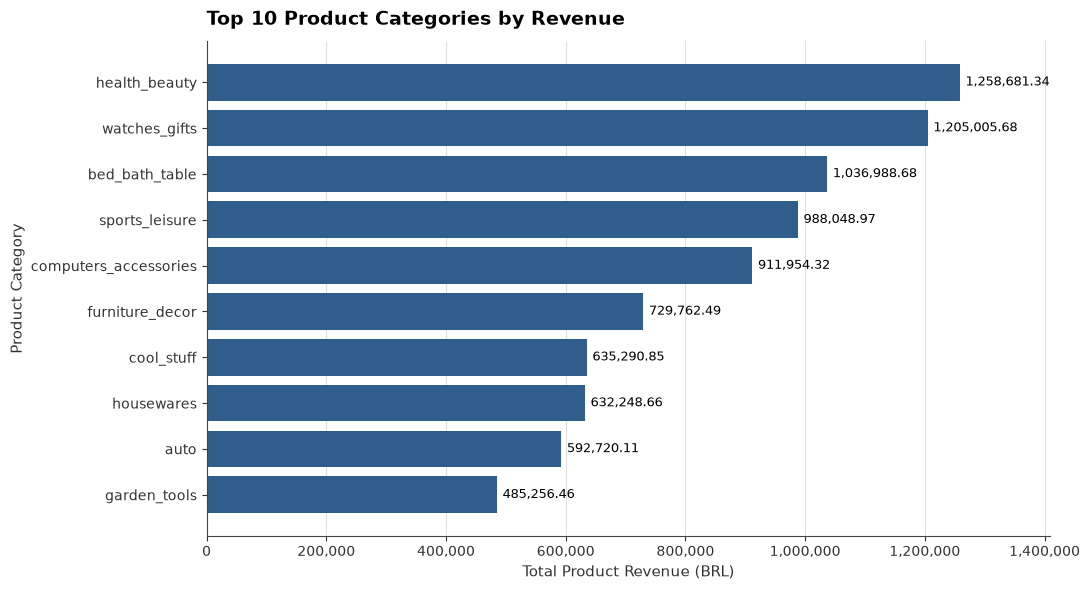

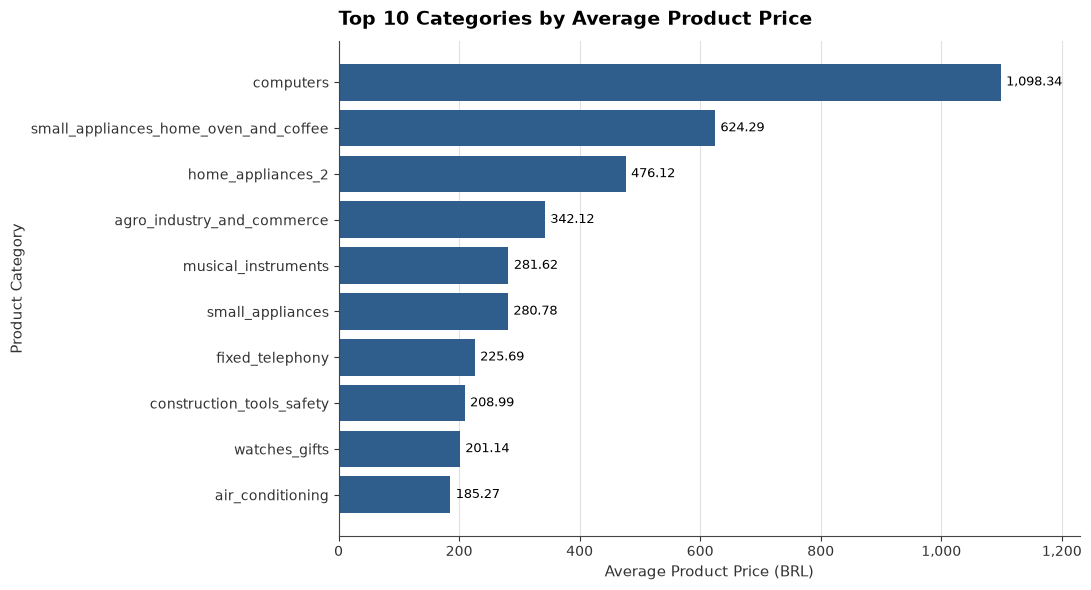

In [52]:
category_charts = [
    ('total_items_sold', 'Top 10 Product Categories by Items Sold', 'Number of Items Sold'),
    ('total_sales', 'Top 10 Product Categories by Revenue', 'Total Product Revenue (BRL)'),
    ('average_price', 'Top 10 Categories by Average Product Price', 'Average Product Price (BRL)'),
]

for column, title, xlabel in category_charts:
    top_categories = category_analysis.nlargest(TOP_N, column).set_index('product_category_name_english')
    plot_barh_top(top_categories[column], title, xlabel, 'Product Category')

**Takeaway.** health_beauty (R$ 1.26M), watches_gifts (R$ 1.21M), and bed_bath_table (R$ 1.04M) lead revenue. bed_bath_table sells the most units (11,115), while watches_gifts reaches second place with only 5,991 items because its average price is R$ 201.

### 6.6 Sellers

Who are the top sellers, and where are sellers located? Seller IDs are shortened to their first 8 characters in charts for readability.

#### 6.6.1 Seller Summary

In [53]:
df_seller_analysis = df_order_items.merge(df_sellers, on='seller_id', how='left')

assert len(df_seller_analysis) == len(df_order_items)
print('Items without seller data:', df_seller_analysis['seller_city'].isna().sum())

seller_analysis = (
    df_seller_analysis
    .groupby(['seller_id', 'seller_city', 'seller_state'])
    .agg(
        total_items_sold=('order_item_id', 'count'),
        total_sales=('price', 'sum'),
        average_price=('price', 'mean'),
        unique_orders=('order_id', 'nunique'),
        unique_products=('product_id', 'nunique'),
    )
    .reset_index()
    .sort_values('total_sales', ascending=False)
)

print('Seller table shape:', seller_analysis.shape)
seller_analysis.head(TOP_N)

Items without seller data: 0
Seller table shape: (3095, 8)


,seller_id,seller_city,seller_state,total_items_sold,total_sales,average_price,unique_orders,unique_products
857,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1156,229472.63,198.505735,1132,95
1013,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,410,222776.05,543.356220,358,23
881,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1987,200472.92,100.892260,1806,399
3024,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,586,194042.03,331.129744,585,289
1535,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,1364,187923.89,137.774113,982,198
1560,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,340,176431.87,518.917265,336,186
2643,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1551,160236.57,103.311779,1314,222
1505,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1171,141745.53,121.046567,1160,149
192,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,1428,138968.55,97.316912,915,154
1824,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1499,135171.70,90.174583,1287,104


#### 6.6.2 Top Sellers

By items sold, by revenue, and by average price. The average-price ranking only includes sellers with at least `MIN_ITEMS_PER_SELLER` items sold.

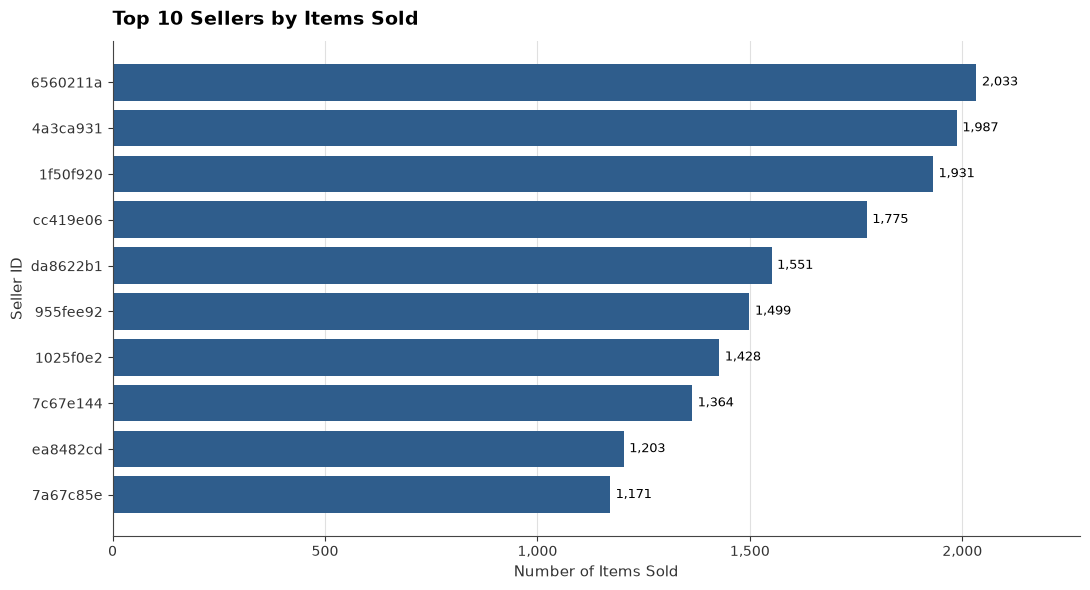

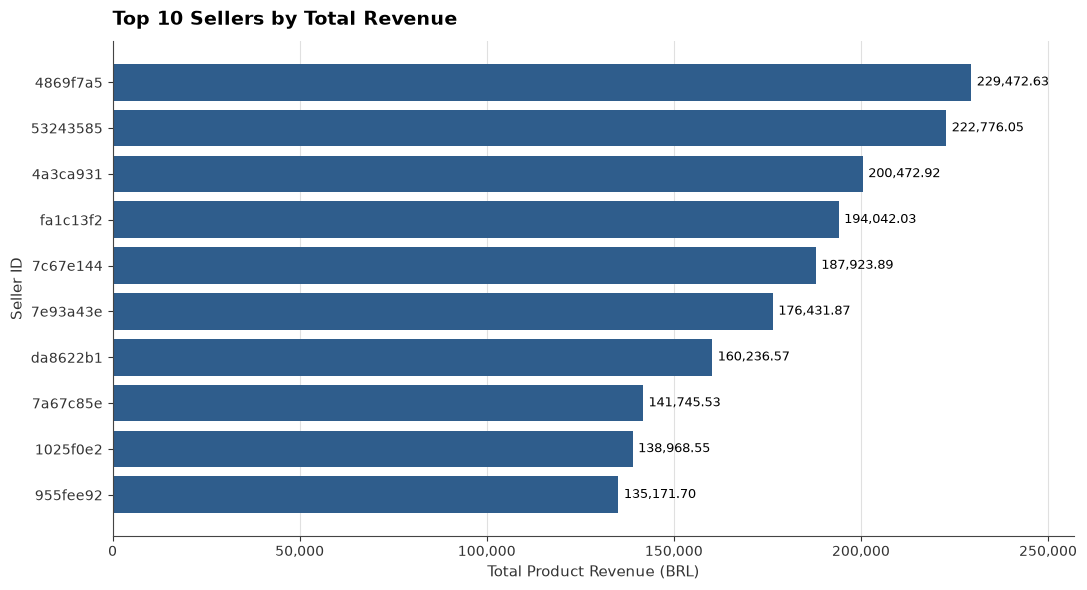

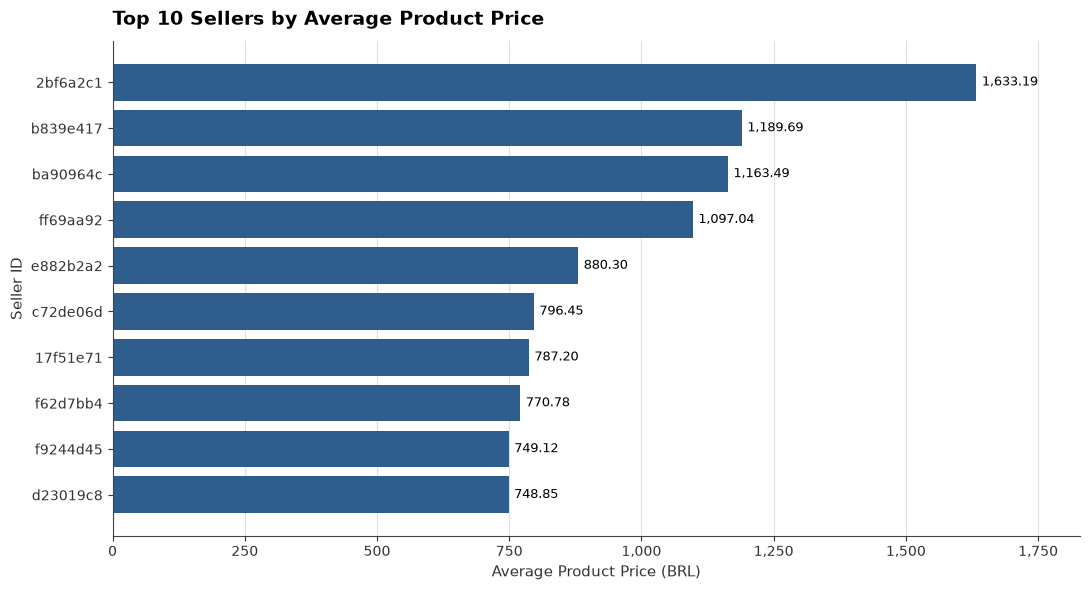

In [54]:
seller_by_id = seller_analysis.set_index('seller_id')

seller_charts = [
    (seller_by_id, 'total_items_sold', 'Top 10 Sellers by Items Sold', 'Number of Items Sold'),
    (seller_by_id, 'total_sales', 'Top 10 Sellers by Total Revenue', 'Total Product Revenue (BRL)'),
    (
        seller_by_id[seller_by_id['total_items_sold'] >= MIN_ITEMS_PER_SELLER],
        'average_price', 'Top 10 Sellers by Average Product Price', 'Average Product Price (BRL)',
    ),
]

for data, column, title, xlabel in seller_charts:
    plot_barh_top(
        data[column].nlargest(TOP_N), title, xlabel, 'Seller ID', max_label_len=8,
    )

#### 6.6.3 Sellers by State

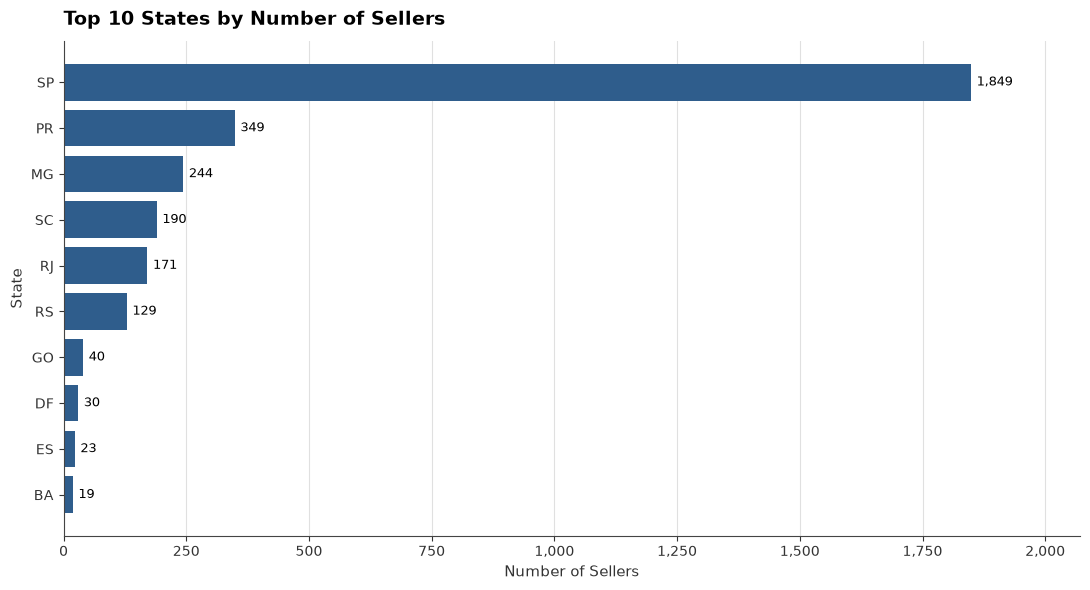

In [55]:
sellers_by_state = df_sellers['seller_state'].value_counts().head(TOP_N)

plot_barh_top(
    sellers_by_state, 'Top 10 States by Number of Sellers', 'Number of Sellers', 'State',
)

**Takeaway.** Sellers are geographically concentrated: Sao Paulo state hosts 1,849 of 3,095 sellers (60%), followed by Parana (349) and Minas Gerais (244). This is consistent with the longer delivery times seen in distant regions in section 6.2.

### 6.7 Customer Reviews

How satisfied are customers, and what drives dissatisfaction? An order can have more than one review, so order-level analysis first aggregates reviews to one row per order.

#### 6.7.1 Prepare Review Data

- Parse review timestamps.
- `response_time_days`: days between the survey being sent (`review_creation_date`) and answered (`review_answer_timestamp`).
- `review_category`: Negative (score up to `NEGATIVE_MAX_SCORE`), Neutral (3), or Positive (4 and 5).

In [56]:
for column in ['review_creation_date', 'review_answer_timestamp']:
    df_order_reviews[column] = pd.to_datetime(df_order_reviews[column], errors='coerce')

df_order_reviews['response_time_days'] = (
    df_order_reviews['review_answer_timestamp'] - df_order_reviews['review_creation_date']
) / ONE_DAY

df_order_reviews['response_time_group'] = pd.cut(
    df_order_reviews['response_time_days'],
    bins=[0, 1, 2, 3, 7, 14, np.inf],
    labels=['0-1 Day', '1-2 Days', '2-3 Days', '3-7 Days', '7-14 Days', '14+ Days'],
    include_lowest=True,
)

df_order_reviews['review_month'] = df_order_reviews['review_creation_date'].dt.to_period('M')

df_order_reviews['review_category'] = pd.cut(
    df_order_reviews['review_score'],
    bins=[0, NEGATIVE_MAX_SCORE, 3, 5],
    labels=['Negative', 'Neutral', 'Positive'],
)

df_order_reviews[[
    'review_score', 'review_category', 'response_time_days', 'response_time_group', 'review_month',
]].head()

,review_score,review_category,response_time_days,response_time_group,review_month
0,4,Positive,0.907627,0-1 Day,2018-01
1,5,Positive,1.128623,1-2 Days,2018-03
2,5,Positive,1.608611,1-2 Days,2018-02
3,5,Positive,0.918125,0-1 Day,2017-04
4,5,Positive,1.435336,1-2 Days,2018-03


#### 6.7.2 Score Distribution

,reviews,percentage
review_score,,
1,11424,11.51
2,3151,3.18
3,8179,8.24
4,19142,19.29
5,57328,57.78


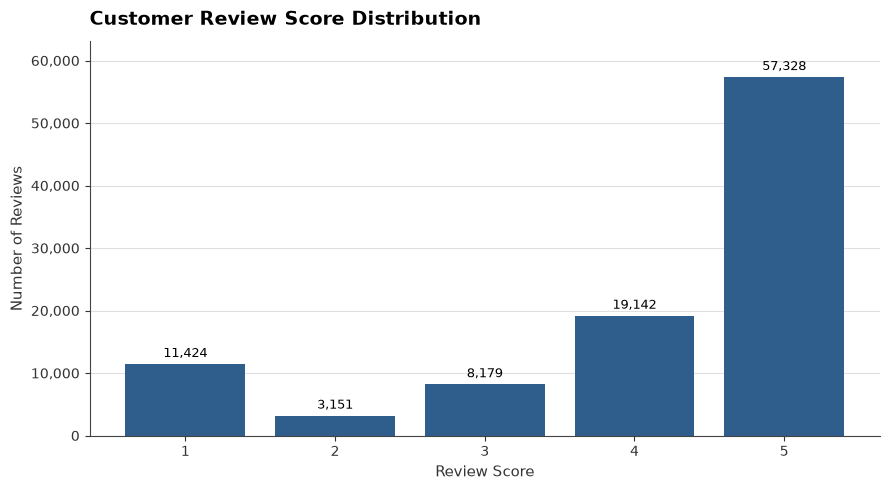

In [57]:
score_distribution = df_order_reviews['review_score'].value_counts().sort_index().to_frame('reviews')
score_distribution['percentage'] = (
    score_distribution['reviews'] / score_distribution['reviews'].sum() * 100
).round(2)

display(score_distribution)

plot_bar(
    score_distribution.index, score_distribution['reviews'],
    'Customer Review Score Distribution', 'Review Score', 'Number of Reviews',
)

Share of reviews by sentiment category:

In [58]:
review_category_analysis = df_order_reviews['review_category'].value_counts().to_frame('total_reviews')
review_category_analysis['percentage'] = (
    review_category_analysis['total_reviews'] / len(df_order_reviews) * 100
).round(2)

review_category_analysis

,total_reviews,percentage
review_category,,
Positive,76470,77.07
Negative,14575,14.69
Neutral,8179,8.24


**Takeaway.** Reviews are polarized: 57.8% are five stars, yet 11.5% are one star, more than three times the share of two-star reviews (3.2%). Overall 77.1% of reviews are positive and 14.7% are negative.

#### 6.7.3 Duplicate Reviews

Some orders have several reviews, and some `review_id` values appear more than once. The check below shows whether a repeated `review_id` is reused across different orders or with different scores. Order-level analysis handles this by averaging scores per order.

In [59]:
print('Rows                          :', len(df_order_reviews))
print('Duplicate order_id rows       :', df_order_reviews['order_id'].duplicated().sum())
print('Orders with several reviews   :', df_order_reviews.loc[df_order_reviews['order_id'].duplicated(), 'order_id'].nunique())
print('Duplicate review_id rows      :', df_order_reviews['review_id'].duplicated().sum())
print('Exact duplicate rows          :', df_order_reviews.duplicated().sum())

duplicate_reviews = df_order_reviews[df_order_reviews['review_id'].duplicated(keep=False)]

duplicate_check = duplicate_reviews.groupby('review_id').agg(
    orders=('order_id', 'nunique'),
    scores=('review_score', 'nunique'),
    comments=('review_comment_message', 'nunique'),
)

print('review_id groups              :', len(duplicate_check))
print('Groups spanning several orders:', (duplicate_check['orders'] > 1).sum())
print('Groups with different scores  :', (duplicate_check['scores'] > 1).sum())

Rows                          : 99224
Duplicate order_id rows       : 551
Orders with several reviews   : 547
Duplicate review_id rows      : 814
Exact duplicate rows          : 0
review_id groups              : 789
Groups spanning several orders: 789
Groups with different scores  : 0


#### 6.7.4 Aggregate Reviews per Order

`is_negative` flags orders whose average review score is at or below `NEGATIVE_MAX_SCORE`.

In [60]:
reviews_by_order = (
    df_order_reviews
    .groupby('order_id')
    .agg(
        avg_review_score=('review_score', 'mean'),
        review_count=('review_score', 'count'),
    )
    .reset_index()
)
reviews_by_order['is_negative'] = reviews_by_order['avg_review_score'] <= NEGATIVE_MAX_SCORE

print('Rows         :', len(reviews_by_order))
print('Unique orders:', reviews_by_order['order_id'].nunique())

reviews_by_order.head()

Rows         : 98673
Unique orders: 98673


,order_id,avg_review_score,review_count,is_negative
0,00010242fe8c5a6d1ba2dd792cb16214,5.0,1,False
1,00018f77f2f0320c557190d7a144bdd3,4.0,1,False
2,000229ec398224ef6ca0657da4fc703e,5.0,1,False
3,00024acbcdf0a6daa1e931b038114c75,4.0,1,False
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0,1,False


#### 6.7.5 Response Time

How quickly customers answer the satisfaction survey, overall and by score.

In [61]:
display(df_order_reviews['response_time_days'].describe().to_frame())

display(df_order_reviews['response_time_group'].value_counts().sort_index().to_frame('total_reviews'))

df_order_reviews.groupby('review_score').agg(
    avg_response_days=('response_time_days', 'mean'),
    median_response_days=('response_time_days', 'median'),
    total_reviews=('review_id', 'count'),
).round(2)

,response_time_days
count,99224.000000
mean,3.148993
std,9.890049
min,0.089225
25%,1.004870
50%,1.674948
75%,3.103565
max,518.699213


,total_reviews
response_time_group,
0-1 Day,24361
1-2 Days,30995
2-3 Days,15898
3-7 Days,23056
7-14 Days,3086
14+ Days,1828


,avg_response_days,median_response_days,total_reviews
review_score,,,
1,3.05,1.55,11424
2,3.00,1.70,3151
3,2.98,1.76,8179
4,3.12,1.79,19142
5,3.21,1.66,57328


#### 6.7.6 Monthly Review Trend

Months with fewer than `MIN_MONTH_SAMPLE` reviews stay in the table but are left out of the chart.

,review_month,avg_review_score,total_reviews
0,2016-10,4.06,179
1,2016-11,3.19,101
2,2016-12,2.36,45
3,2017-01,4.34,239
4,2017-02,4.28,1413
5,2017-03,4.03,2481
6,2017-04,4.04,2055
7,2017-05,4.10,3710
8,2017-06,4.13,3440
9,2017-07,4.18,3503


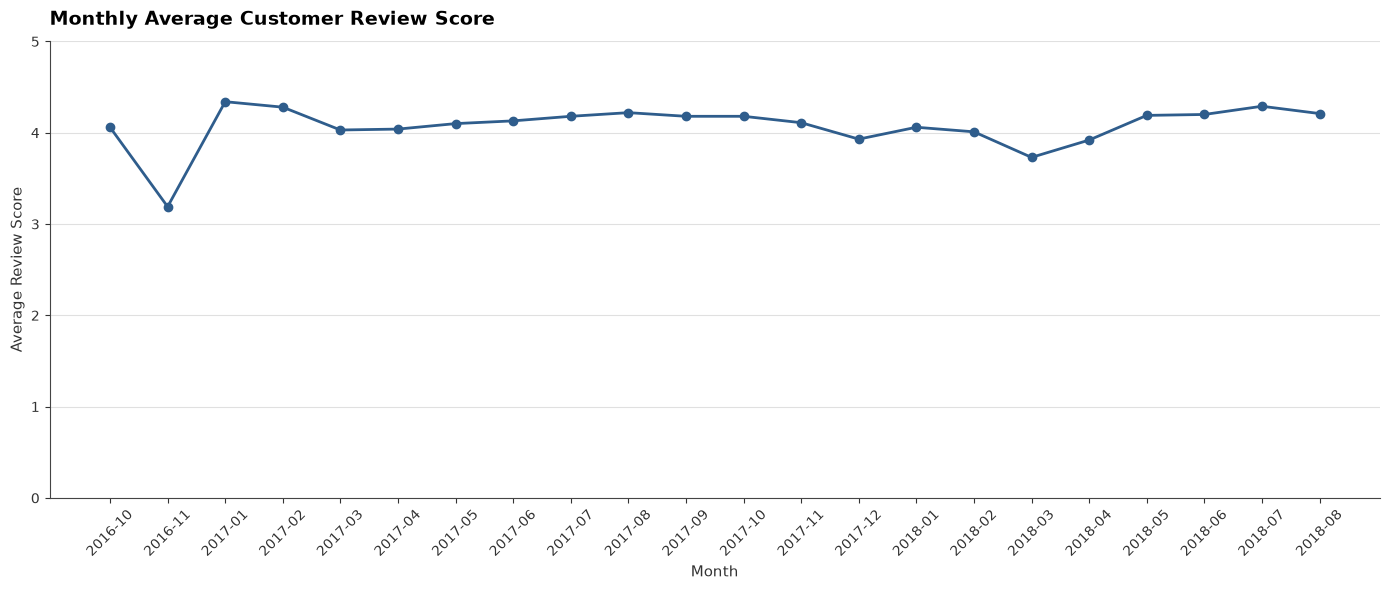

In [62]:
monthly_review_analysis = (
    df_order_reviews
    .groupby('review_month')
    .agg(
        avg_review_score=('review_score', 'mean'),
        total_reviews=('review_id', 'count'),
    )
    .round(2)
    .reset_index()
)
monthly_review_analysis['review_month'] = monthly_review_analysis['review_month'].astype(str)

display(monthly_review_analysis)

monthly_review_chart = monthly_review_analysis[monthly_review_analysis['total_reviews'] >= MIN_MONTH_SAMPLE]

plot_line(
    monthly_review_chart['review_month'], monthly_review_chart['avg_review_score'],
    'Monthly Average Customer Review Score', 'Month', 'Average Review Score',
    figsize=(14, 6), ylim=(0, 5),
)

**Takeaway.** Monthly average scores stay at roughly 4.0 to 4.3 in most months. The lowest points are March 2018 (3.73) and December 2017 (3.93). Reviews are dated after delivery, so these dips follow the late-delivery peaks of February to March 2018 and November 2017.

#### 6.7.7 Reviews vs Delivery Performance

Joins reviews to delivered orders and compares satisfaction between on-time and late deliveries, and across delivery-duration groups. Duration bins are right-inclusive, so `5-10 Days` means more than 5 and up to 10 days.

Delivered orders without a review: 646


,avg_review_score,total_orders
delivery_status,,
Late,2.57,7826
On Time,4.29,88644


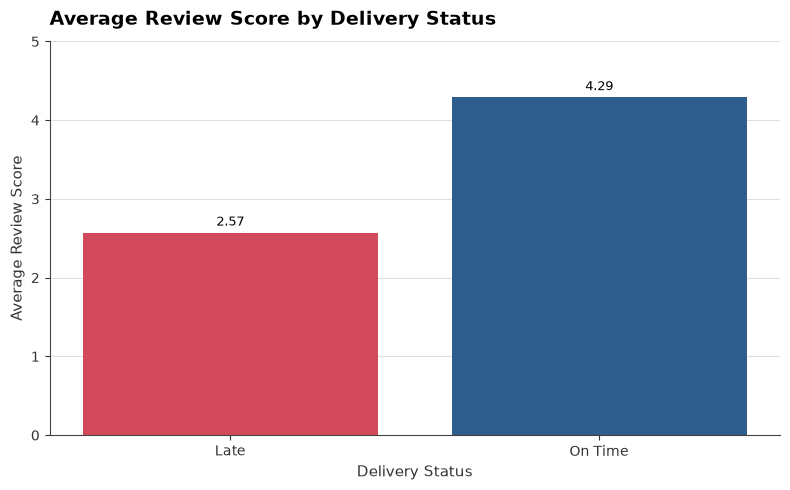

In [63]:
df_review_delivery = df_delivered.merge(reviews_by_order, on='order_id', how='left')

assert len(df_review_delivery) == len(df_delivered)
print('Delivered orders without a review:', df_review_delivery['avg_review_score'].isna().sum())

review_delivery_analysis = (
    df_review_delivery
    .groupby('delivery_status')
    .agg(
        avg_review_score=('avg_review_score', 'mean'),
        total_orders=('order_id', 'count'),
    )
    .round(2)
)

display(review_delivery_analysis)

plot_bar(
    review_delivery_analysis.index, review_delivery_analysis['avg_review_score'],
    'Average Review Score by Delivery Status', 'Delivery Status', 'Average Review Score',
    figsize=(8, 5), ylim=(0, 5),
    color=[ACCENT if status == 'Late' else PRIMARY for status in review_delivery_analysis.index],
)

Average review score by delivery-duration group:

,avg_review_score,total_orders
delivery_duration_group,,
0-5 Days,4.45,13430
5-10 Days,4.36,33050
10-15 Days,4.27,23613
15-20 Days,4.13,12154
20+ Days,3.23,14223


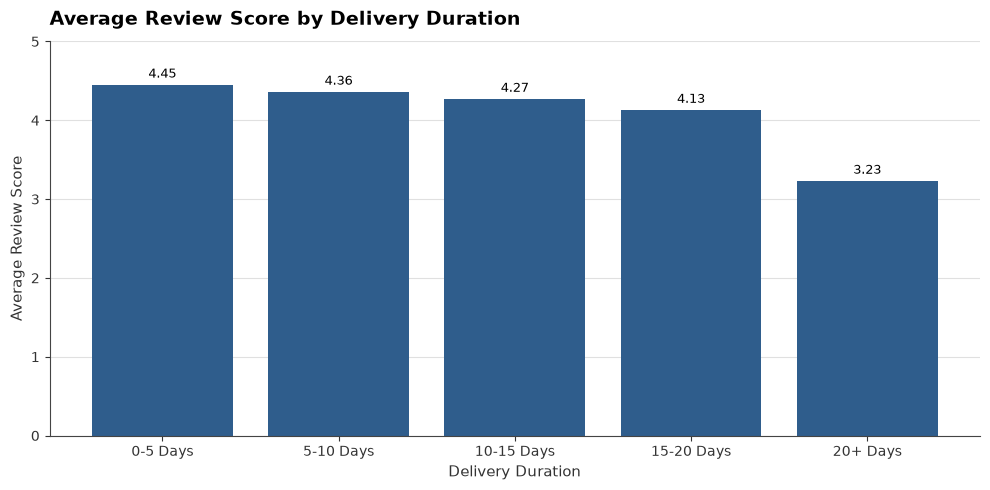

In [64]:
df_review_delivery['delivery_duration_group'] = pd.cut(
    df_review_delivery['delivery_days'],
    bins=[0, 5, 10, 15, 20, np.inf],
    labels=['0-5 Days', '5-10 Days', '10-15 Days', '15-20 Days', '20+ Days'],
    include_lowest=True,
)

duration_review_analysis = (
    df_review_delivery
    .groupby('delivery_duration_group', observed=True)
    .agg(
        avg_review_score=('avg_review_score', 'mean'),
        total_orders=('order_id', 'count'),
    )
    .round(2)
)

display(duration_review_analysis)

plot_bar(
    duration_review_analysis.index, duration_review_analysis['avg_review_score'],
    'Average Review Score by Delivery Duration', 'Delivery Duration', 'Average Review Score',
    figsize=(10, 5), ylim=(0, 5),
)

**Takeaway.** Delivery performance has a strong association with customer satisfaction in this analysis. Late orders average 2.57 against 4.29 for on-time orders, and orders delivered in 20 or more days (14,223 orders) average 3.23 against 4.45 for delivery within 5 days. This is an association, not proof of causation.

#### 6.7.8 Negative Reviews by City

Share of reviewed orders with a negative average score, per customer city. Rankings only include cities with at least `MIN_CITY_SAMPLE` reviewed orders.

In [65]:
review_city = reviews_by_order.merge(
    df_master[['order_id', 'customer_city']], on='order_id', how='left'
)

city_negative = (
    review_city
    .groupby('customer_city')
    .agg(
        reviewed_orders=('order_id', 'nunique'),
        negative_orders=('is_negative', 'sum'),
    )
)
city_negative['negative_rate'] = (
    city_negative['negative_orders'] / city_negative['reviewed_orders'] * 100
).round(2)

city_negative[city_negative['reviewed_orders'] >= MIN_CITY_SAMPLE].nlargest(TOP_N, 'negative_rate')

,reviewed_orders,negative_orders,negative_rate
customer_city,,,
maceio,245,68,27.76
rio das ostras,136,37,27.21
cabo frio,114,30,26.32
sao goncalo,402,105,26.12
macae,235,61,25.96
belford roxo,109,27,24.77
sao jose,167,41,24.55
nova friburgo,151,37,24.50
nova iguacu,438,104,23.74


**Takeaway.** The cities with the highest negative-review rates are largely the same ones with the highest late-delivery rates: Maceio, Sao Goncalo, Cabo Frio, Sao Joao de Meriti, Nova Friburgo, and Rio das Ostras appear in both rankings. Maceio has the highest negative-review rate (27.8%), against 14.7% negative reviews overall.

#### 6.7.9 Negative Reviews by Category

An order containing items from several categories counts once in each of those categories. Rankings only include categories with at least `MIN_CITY_SAMPLE` reviewed orders.

,reviewed_orders,negative_orders,negative_rate
product_category_name_english,,,
fashion_male_clothing,111,29,26.13
office_furniture,1263,286,22.64
audio,347,76,21.90
construction_tools_safety,166,34,20.48
home_confort,395,76,19.24
fixed_telephony,214,40,18.69
fashion_underwear_beach,120,22,18.33
home_construction,487,86,17.66
bed_bath_table,9313,1549,16.63


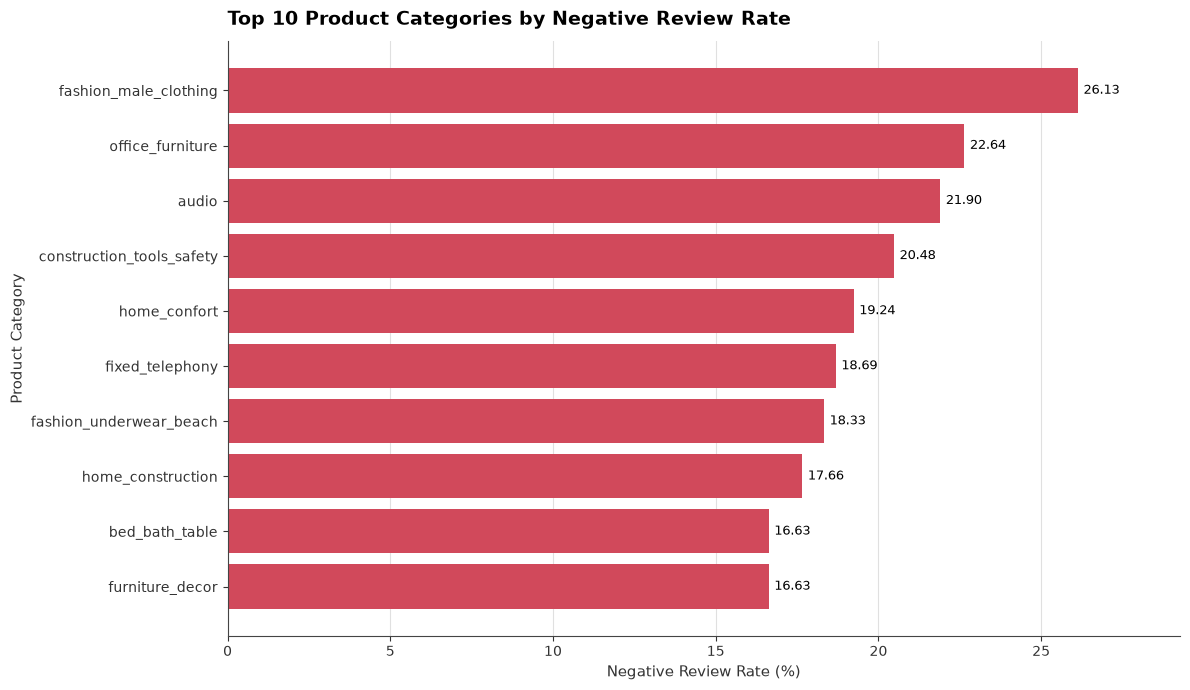

In [66]:
category_order_reviews = (
    df_items_analysis[['order_id', 'product_category_name_english']]
    .dropna(subset=['product_category_name_english'])
    .drop_duplicates()
    .merge(reviews_by_order[['order_id', 'is_negative']], on='order_id', how='inner')
)

category_negative = (
    category_order_reviews
    .groupby('product_category_name_english')
    .agg(
        reviewed_orders=('order_id', 'nunique'),
        negative_orders=('is_negative', 'sum'),
    )
)
category_negative['negative_rate'] = (
    category_negative['negative_orders'] / category_negative['reviewed_orders'] * 100
).round(2)

top_negative_categories = (
    category_negative[category_negative['reviewed_orders'] >= MIN_CITY_SAMPLE]
    .nlargest(TOP_N, 'negative_rate')
)

display(top_negative_categories)

plot_barh_top(
    top_negative_categories['negative_rate'],
    'Top 10 Product Categories by Negative Review Rate',
    'Negative Review Rate (%)', 'Product Category', figsize=(12, 7), color=ACCENT,
)

**Takeaway.** fashion_male_clothing (26.1%), office_furniture (22.6%), and audio (21.9%) have the highest negative-review rates. office_furniture is the most reliable signal, with 1,263 reviewed orders against 111 for fashion_male_clothing.

#### 6.7.10 Reviews vs Product Price

Average review score by the average item price of the order.

,price_range,total_orders,avg_review_score
0,0-50,32403,4.12
1,50-100,28817,4.09
2,100-200,24222,4.12
3,200-500,9426,4.07
4,500-1000,2250,4.04
5,1000+,799,4.00


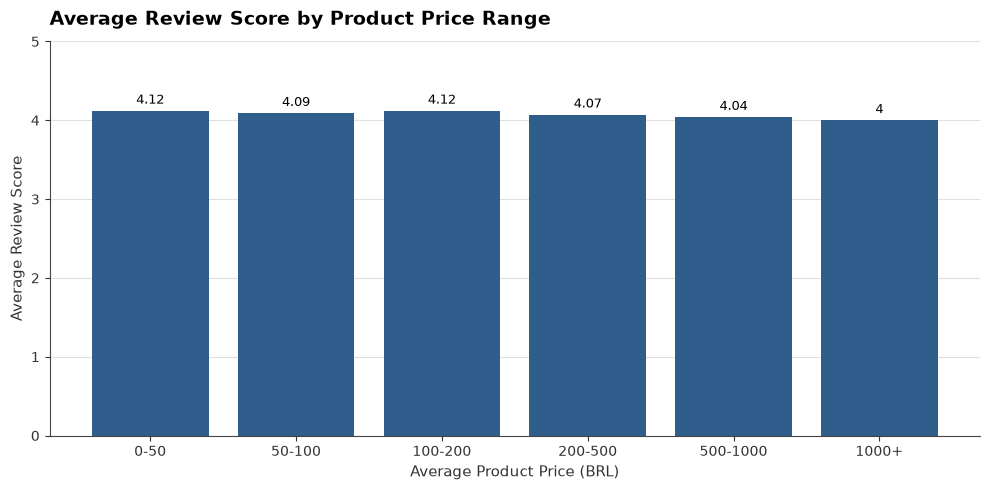

In [67]:
order_avg_price = (
    df_order_items
    .groupby('order_id')['price']
    .mean()
    .rename('avg_product_price')
    .reset_index()
)

df_price_reviews = order_avg_price.merge(reviews_by_order, on='order_id', how='inner')

df_price_reviews['price_range'] = pd.cut(
    df_price_reviews['avg_product_price'],
    bins=[0, 50, 100, 200, 500, 1000, np.inf],
    labels=['0-50', '50-100', '100-200', '200-500', '500-1000', '1000+'],
    include_lowest=True,
)

price_review_analysis = (
    df_price_reviews
    .groupby('price_range', observed=True)
    .agg(
        total_orders=('order_id', 'nunique'),
        avg_review_score=('avg_review_score', 'mean'),
    )
    .round(2)
    .reset_index()
)

display(price_review_analysis)

plot_bar(
    price_review_analysis['price_range'], price_review_analysis['avg_review_score'],
    'Average Review Score by Product Price Range', 'Average Product Price (BRL)',
    'Average Review Score', figsize=(10, 5), ylim=(0, 5),
)

**Takeaway.** Review scores are flat across price ranges (4.12 for orders under R$ 50 and 4.00 for orders above R$ 1,000), so this analysis does not show a clear relationship between product price and dissatisfaction.

## 7. KPI Summary and Business Insights

Headline metrics, all computed from the tables built above so they always stay consistent with the analysis.

### 7.1 Compute KPIs

Order counts use `df_master`, delivery metrics use `df_delivered`, and review metrics use the review-level table.

In [68]:
status_counts = df_master['order_status'].value_counts()

total_orders = df_master['order_id'].nunique()
delivered_orders = int(status_counts.get('delivered', 0))
canceled_orders = int(status_counts.get('canceled', 0))
unavailable_orders = int(status_counts.get('unavailable', 0))

total_payment_value = df_master['total_payment'].sum()
average_order_value = df_master['total_payment'].mean()
average_items_per_order = df_master['total_items'].mean()

average_delivery_time = df_delivered['delivery_days'].mean()
on_time_rate = (~df_delivered['is_late']).mean() * 100
late_delivery_rate = df_delivered['is_late'].mean() * 100

review_rates = df_order_reviews['review_category'].value_counts(normalize=True) * 100
average_review_score = df_order_reviews['review_score'].mean()
positive_reviews_rate = review_rates.get('Positive', 0.0)
negative_reviews_rate = review_rates.get('Negative', 0.0)

kpis = [
    ('Total Orders', total_orders, f'{total_orders:,}'),
    ('Delivered Orders', delivered_orders, f'{delivered_orders:,}'),
    ('Delivered Rate', delivered_orders / total_orders * 100, f'{delivered_orders / total_orders * 100:.2f}%'),
    ('Canceled Orders', canceled_orders, f'{canceled_orders:,}'),
    ('Canceled Rate', canceled_orders / total_orders * 100, f'{canceled_orders / total_orders * 100:.2f}%'),
    ('Unavailable Orders', unavailable_orders, f'{unavailable_orders:,}'),
    ('Unavailable Rate', unavailable_orders / total_orders * 100, f'{unavailable_orders / total_orders * 100:.2f}%'),
    ('Total Payment Value', total_payment_value, f'R$ {total_payment_value:,.2f}'),
    ('Average Order Value', average_order_value, f'R$ {average_order_value:,.2f}'),
    ('Average Items Per Order', average_items_per_order, f'{average_items_per_order:.2f}'),
    ('Average Delivery Time', average_delivery_time, f'{average_delivery_time:.2f} Days'),
    ('On-Time Delivery Rate', on_time_rate, f'{on_time_rate:.2f}%'),
    ('Late Delivery Rate', late_delivery_rate, f'{late_delivery_rate:.2f}%'),
    ('Average Review Score', average_review_score, f'{average_review_score:.2f} / 5'),
    ('Positive Reviews Rate', positive_reviews_rate, f'{positive_reviews_rate:.2f}%'),
    ('Negative Reviews Rate', negative_reviews_rate, f'{negative_reviews_rate:.2f}%'),
]

kpi_summary = pd.DataFrame(kpis, columns=['KPI', 'Value', 'Formatted Value'])

kpi_summary[['KPI', 'Formatted Value']]

,KPI,Formatted Value
0,Total Orders,"99,441"
1,Delivered Orders,"96,478"
2,Delivered Rate,97.02%
3,Canceled Orders,625
4,Canceled Rate,0.63%
5,Unavailable Orders,609
6,Unavailable Rate,0.61%
7,Total Payment Value,"R$ 16,008,872.12"
8,Average Order Value,R$ 160.99
9,Average Items Per Order,1.14


### 7.2 Business Insights

Key findings with a recommended action for each. Values are pulled from the computed variables, not typed in by hand.

In [69]:
late_orders_review_score = review_delivery_analysis['avg_review_score'].get('Late', np.nan)

business_insights = pd.DataFrame({
    'Area': ['Customers', 'Delivery', 'Delivery', 'Customer Reviews', 'Customer Reviews'],
    'Insight': [
        'Repeat Customer Rate',
        'On-Time Delivery Rate',
        'Late Delivery Rate',
        'Positive Reviews Rate',
        'Late Orders Average Review Score',
    ],
    'Value': [
        round(repeat_customer_rate, 2),
        round(on_time_rate, 2),
        round(late_delivery_rate, 2),
        round(positive_reviews_rate, 2),
        round(late_orders_review_score, 2),
    ],
    'Recommendation': [
        'Launch retention programs such as post-purchase offers and loyalty incentives',
        'Maintain performance and review whether the conservative delivery estimates can be tightened',
        'Add capacity before peak periods and review carriers in the worst-performing regions',
        'Track monthly scores and watch for dips after late-delivery peaks',
        'Treat delivery delays as the main driver of dissatisfaction',
    ],
})

business_insights

,Area,Insight,Value,Recommendation
0,Customers,Repeat Customer Rate,3.12,Launch retention programs such as post-purchas...
1,Delivery,On-Time Delivery Rate,91.89,Maintain performance and review whether the co...
2,Delivery,Late Delivery Rate,8.11,Add capacity before peak periods and review ca...
3,Customer Reviews,Positive Reviews Rate,77.07,Track monthly scores and watch for dips after ...
4,Customer Reviews,Late Orders Average Review Score,2.57,Treat delivery delays as the main driver of di...


## 8. Export

Writes the analysis tables to CSV files in the output directory and bundles them into a single ZIP archive. Numeric columns are rounded to two decimals in the exported files only; the DataFrames in memory are left untouched.

### 8.1 Prepare Delivery and Review Datasets

In [70]:
delivery_analysis = df_delivered[[
    'order_id',
    'customer_id',
    'customer_city',
    'customer_state',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'delivery_days',
    'delivery_difference',
    'delivery_status',
]].copy()

review_analysis = df_order_reviews[[
    'review_id',
    'order_id',
    'review_score',
    'review_category',
    'review_comment_title',
    'review_comment_message',
    'review_creation_date',
    'review_answer_timestamp',
    'response_time_days',
    'response_time_group',
    'review_month',
]].copy()

print('Delivery dataset:', delivery_analysis.shape)
print('Review dataset  :', review_analysis.shape)

Delivery dataset: (96470, 10)
Review dataset  : (99224, 11)


### 8.2 Write CSV Files

In [71]:
exports = {
    'olist_kpi_summary.csv': kpi_summary,
    'olist_monthly_sales.csv': monthly_sales,
    'olist_city_sales.csv': city_sales,
    'olist_customer_analysis.csv': customer_orders,
    'olist_customer_summary.csv': customer_summary,
    'olist_delivery_analysis.csv': delivery_analysis,
    'olist_product_category_analysis.csv': category_analysis,
    'olist_seller_analysis.csv': seller_analysis,
    'olist_review_analysis.csv': review_analysis,
}

exported_paths = []
export_log = []

for file_name, df in exports.items():
    path = OUTPUT_DIR / file_name
    df_out = df.copy()
    numeric_columns = df_out.select_dtypes(include='number').columns
    df_out[numeric_columns] = df_out[numeric_columns].round(2)
    df_out.to_csv(path, index=False, encoding='utf-8-sig')
    exported_paths.append(path)
    export_log.append({'file': file_name, 'rows': df.shape[0], 'columns': df.shape[1]})

pd.DataFrame(export_log)

,file,rows,columns
0,olist_kpi_summary.csv,16,3
1,olist_monthly_sales.csv,25,4
2,olist_city_sales.csv,4119,4
3,olist_customer_analysis.csv,96096,4
4,olist_customer_summary.csv,4,2
5,olist_delivery_analysis.csv,96470,10
6,olist_product_category_analysis.csv,71,6
7,olist_seller_analysis.csv,3095,8
8,olist_review_analysis.csv,99224,11


### 8.3 Create ZIP Archive

In [72]:
zip_path = OUTPUT_DIR / 'olist_analysis_datasets.zip'

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path, arcname=path.name)

print('ZIP file created:', zip_path)
print('Files included  :', len(exported_paths))
print('ZIP size (MB)   :', round(zip_path.stat().st_size / (1024 * 1024), 2))

ZIP file created: output\olist_analysis_datasets.zip
Files included  : 9
ZIP size (MB)   : 15.05


## 9. Advanced Customer Analytics

This section extends the original exploratory analysis with **cohort retention** and **RFM customer segmentation**. It uses delivered orders to focus on completed customer experiences. Monetary value is based on recorded payment value for those delivered orders; it should be interpreted as an order-payment proxy, not accounting profit or net revenue.

### 9.1 Define the Analysis Population

For retention and RFM, include delivered orders with a valid purchase timestamp and a known `customer_unique_id`. This avoids treating canceled or unavailable orders as completed purchases.

In [73]:
customer_tx = df_master.loc[
    (df_master['order_status'] == 'delivered')
    & df_master['order_purchase_timestamp'].notna()
    & df_master['customer_unique_id'].notna(),
    ['order_id', 'customer_unique_id', 'order_purchase_timestamp', 'total_payment'],
].copy()

customer_tx['order_month'] = customer_tx['order_purchase_timestamp'].dt.to_period('M')
print(f"Delivered transactions: {len(customer_tx):,}")
print(f"Unique customers      : {customer_tx['customer_unique_id'].nunique():,}")
print(f"Purchase months       : {customer_tx['order_month'].nunique():,}")

Delivered transactions: 96,478
Unique customers      : 93,358
Purchase months       : 23


### 9.2 Cohort Retention Analysis

A cohort is defined by the month of a customer's first delivered purchase. Retention for month *n* is the share of that cohort that placed at least one additional delivered order in cohort month + *n*. Month 0 is 100% by definition. Because the dataset ends in 2018, recent cohorts have fewer observable months; compare only columns with sufficient follow-up.

,cohort_customers
cohort_month,
2017-09,4004
2017-10,4328
2017-11,7060
2017-12,5338
2018-01,6842
2018-02,6288
2018-03,6774
2018-04,6582
2018-05,6506


cohort_index,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2017-09,100.0,0.7,0.5,0.3,0.4,0.2,0.2,0.2,0.3,0.2,0.2,0.1
2017-10,100.0,0.7,0.3,0.1,0.2,0.2,0.2,0.4,0.3,0.2,0.2,0.0
2017-11,100.0,0.6,0.4,0.2,0.2,0.2,0.1,0.2,0.1,0.1,0.0,0.0
2017-12,100.0,0.2,0.3,0.3,0.3,0.2,0.2,0.0,0.2,0.0,0.0,0.0
2018-01,100.0,0.3,0.4,0.3,0.3,0.2,0.2,0.2,0.0,0.0,0.0,0.0
2018-02,100.0,0.3,0.4,0.3,0.3,0.2,0.2,0.0,0.0,0.0,0.0,0.0
2018-03,100.0,0.4,0.3,0.3,0.1,0.1,0.0,0.0,0.0,0.0,0.0,0.0
2018-04,100.0,0.6,0.3,0.2,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018-05,100.0,0.5,0.3,0.2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


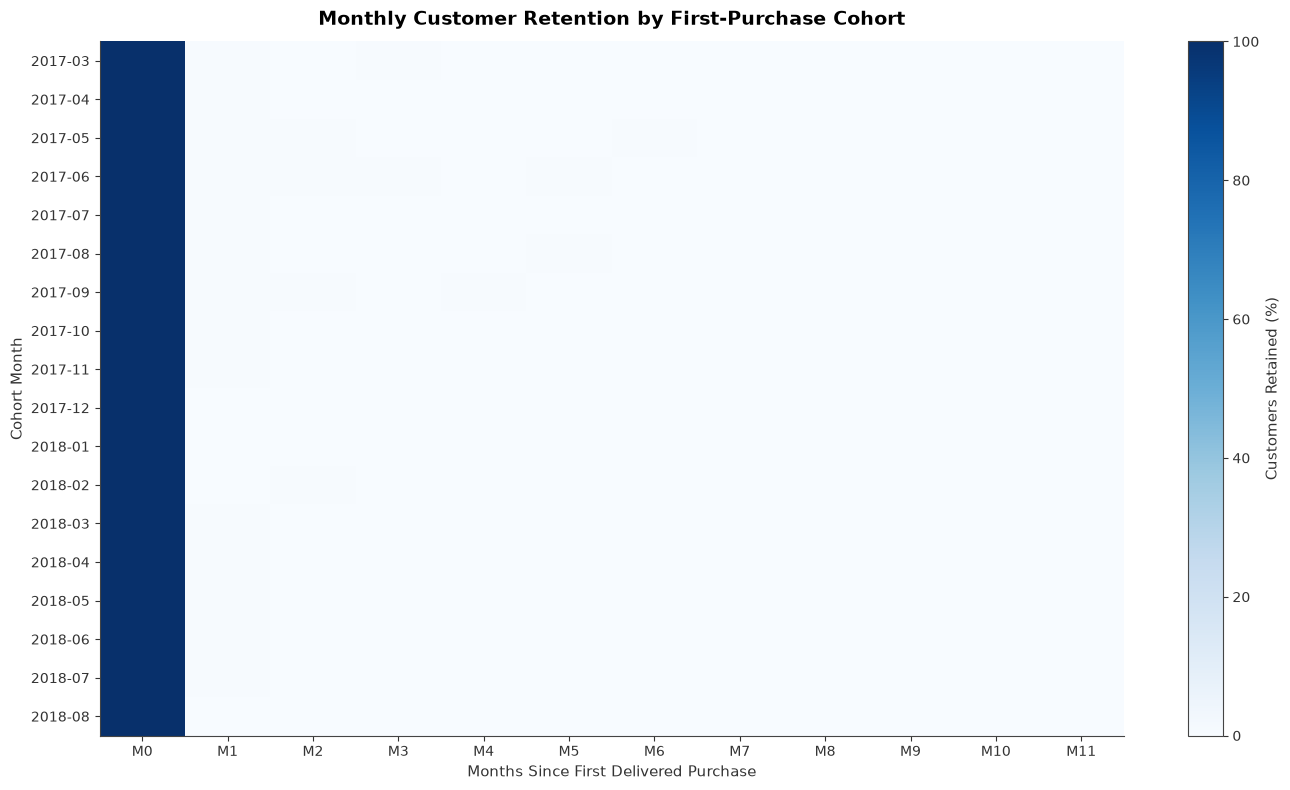

In [74]:
first_purchase = (
    customer_tx.groupby('customer_unique_id')['order_month']
    .min().rename('cohort_month')
)
cohort_tx = customer_tx.join(first_purchase, on='customer_unique_id')
cohort_tx['cohort_index'] = (
    (cohort_tx['order_month'].dt.year - cohort_tx['cohort_month'].dt.year) * 12
    + (cohort_tx['order_month'].dt.month - cohort_tx['cohort_month'].dt.month)
)

cohort_counts = (
    cohort_tx.groupby(['cohort_month', 'cohort_index'])['customer_unique_id']
    .nunique().unstack(fill_value=0).sort_index()
)
cohort_sizes = cohort_counts.iloc[:, 0]
cohort_retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

# Keep the first 12 months for a readable and comparable retention view.
cohort_retention_12m = cohort_retention.reindex(columns=range(12))
cohort_retention_12m.index = cohort_retention_12m.index.astype(str)

display(cohort_sizes.rename('cohort_customers').to_frame().tail(12))
display(cohort_retention_12m.round(1).tail(12))

fig, ax = plt.subplots(figsize=(14, 8))
image = ax.imshow(cohort_retention_12m.tail(18).to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='Blues')
ax.set_xticks(range(12), labels=[f'M{i}' for i in range(12)])
ax.set_yticks(range(len(cohort_retention_12m.tail(18))), labels=cohort_retention_12m.tail(18).index)
ax.set_title('Monthly Customer Retention by First-Purchase Cohort')
ax.set_xlabel('Months Since First Delivered Purchase')
ax.set_ylabel('Cohort Month')
fig.colorbar(image, ax=ax, label='Customers Retained (%)')
plt.tight_layout()
plt.show()

**Takeaway.** Returning is rare even in the first month: across the cohorts from September 2017 to July 2018, month-1 retention ranges from 0.2% to 0.7%, and later months rarely exceed 0.5%. The 2018-08 cohort has no follow-up window yet, so its later columns are empty by construction, not low retention.

### 9.3 RFM Customer Segmentation

RFM summarizes customer behavior using:
- **Recency:** days since the customer's most recent delivered purchase.
- **Frequency:** number of distinct delivered orders.
- **Monetary:** sum of recorded payment values for delivered orders.

**Design note.** About 97% of customers placed a single order, so frequency is almost constant. Scoring it in quintiles would split identical customers into different groups by row order, and the resulting segment names would not match real behavior. Therefore:

- Recency (R) and Monetary (M) are continuous, so they are scored 1 to 5 by quintile (for recency, 5 means most recent).
- Frequency (F) uses fixed buckets: 1 order, 2 orders, 3 or more orders.
- Segments are rule-based. Customers with 2 or more orders are *Repeat* customers, split by recency. One-time customers are split by recency and monetary value.

The cell asserts that every *Repeat* segment contains only customers with at least 2 orders, and that every other segment contains only one-time customers.


Customers with a single delivered order: 97.0%


,customers,avg_recency_days,avg_frequency,avg_monetary,total_monetary,customer_share_pct
segment,,,,,,
Lapsed One-Time,22570,396.16,1.00,72.70,1640928.88,24.18
New Customers,21734,90.33,1.00,72.93,1585043.03,23.28
Mid-Term One-Time,18070,220.48,1.00,151.48,2737198.64,19.36
New High-Value,14406,91.90,1.00,302.27,4354527.69,15.43
Lapsed High-Value,13777,394.35,1.00,307.79,4240406.32,14.76
Repeat - Active,1805,131.91,2.13,315.74,569904.71,1.93
Repeat - Lapsed,996,381.91,2.08,295.64,294452.50,1.07


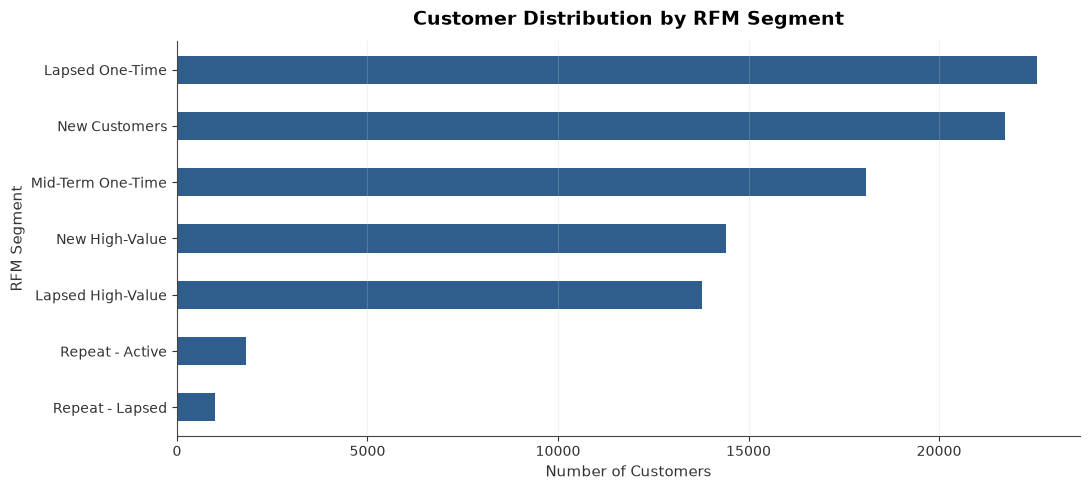

In [75]:
rfm_reference_date = customer_tx['order_purchase_timestamp'].max().normalize() + pd.Timedelta(days=1)
rfm = (
    customer_tx.groupby('customer_unique_id')
    .agg(
        last_purchase=('order_purchase_timestamp', 'max'),
        frequency=('order_id', 'nunique'),
        monetary=('total_payment', 'sum'),
    )
)
rfm['recency_days'] = (rfm_reference_date - rfm['last_purchase'].dt.normalize()).dt.days

print(f"Customers with a single delivered order: {(rfm['frequency'] == 1).mean() * 100:.1f}%")

# Recency and Monetary are continuous: quintile scores. Rank first so ties do not break qcut.
rfm['R'] = pd.qcut(rfm['recency_days'].rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
# Frequency is almost constant, so use fixed buckets: 1, 2, 3+ orders.
rfm['F'] = rfm['frequency'].clip(upper=3).astype(int)
rfm['RFM_score'] = rfm[['R', 'F', 'M']].astype(str).agg(''.join, axis=1)


def assign_rfm_segment(row):
    """Transparent, rule-based segments built on actual order counts."""
    if row['frequency'] >= 2:
        return 'Repeat - Active' if row['R'] >= 3 else 'Repeat - Lapsed'
    if row['R'] >= 4:
        return 'New High-Value' if row['M'] >= 4 else 'New Customers'
    if row['R'] == 3:
        return 'Mid-Term One-Time'
    return 'Lapsed High-Value' if row['M'] >= 4 else 'Lapsed One-Time'


rfm['segment'] = rfm.apply(assign_rfm_segment, axis=1)

# Sanity checks: segment names must match real purchase behavior.
is_repeat = rfm['segment'].str.startswith('Repeat')
assert rfm.loc[is_repeat, 'frequency'].min() >= 2
assert rfm.loc[~is_repeat, 'frequency'].max() == 1

rfm_summary = (
    rfm.groupby('segment')
    .agg(
        customers=('segment', 'size'),
        avg_recency_days=('recency_days', 'mean'),
        avg_frequency=('frequency', 'mean'),
        avg_monetary=('monetary', 'mean'),
        total_monetary=('monetary', 'sum'),
    )
    .sort_values('customers', ascending=False)
)
rfm_summary['customer_share_pct'] = rfm_summary['customers'] / len(rfm) * 100

display(rfm_summary.round(2))

fig, ax = plt.subplots(figsize=(11, 5))
rfm_summary['customers'].sort_values().plot(kind='barh', ax=ax)
ax.set_title('Customer Distribution by RFM Segment')
ax.set_xlabel('Number of Customers')
ax.set_ylabel('RFM Segment')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()


### 9.4 Statistical Test: Delivery Status and Review Scores

The earlier comparison showed lower average reviews for late deliveries. This section tests whether the review-score distributions differ using a two-sided Mann–Whitney U test. The test evaluates a distributional difference; it does **not** establish that delivery delay causes lower scores. With about 96,000 orders almost any difference is statistically significant, so the cell also reports the **rank-biserial correlation** as an effect size: the probability that a random on-time order has a higher score than a random late order, minus the probability of the reverse. Values near 0 mean no difference, and values above roughly 0.5 are conventionally read as large. Only delivered orders with a review and a known delivery status are included.

In [76]:
from scipy.stats import mannwhitneyu

review_test_data = df_review_delivery.dropna(subset=['avg_review_score', 'delivery_status']).copy()
on_time_scores = review_test_data.loc[review_test_data['delivery_status'] == 'On Time', 'avg_review_score']
late_scores = review_test_data.loc[review_test_data['delivery_status'] == 'Late', 'avg_review_score']

if len(on_time_scores) > 0 and len(late_scores) > 0:
    u_stat, p_value = mannwhitneyu(on_time_scores, late_scores, alternative='two-sided')
    n_on_time, n_late = len(on_time_scores), len(late_scores)
    # Rank-biserial correlation: P(on-time > late) - P(on-time < late), ties counted as half.
    rank_biserial = 2 * u_stat / (n_on_time * n_late) - 1
    statistical_test_summary = pd.DataFrame([{
        'test': 'Mann–Whitney U (two-sided)',
        'on_time_orders': n_on_time,
        'late_orders': n_late,
        'on_time_median_score': on_time_scores.median(),
        'late_median_score': late_scores.median(),
        'U_statistic': u_stat,
        'p_value': p_value,
        'p_value_display': '< 0.001' if p_value < 0.001 else f'{p_value:.4f}',
        'rank_biserial_effect_size': rank_biserial,
        'significant_at_0_05': p_value < 0.05,
    }])
    display(statistical_test_summary.round(4))
else:
    print('Not enough observations in both delivery groups to run the test.')


,test,on_time_orders,late_orders,on_time_median_score,late_median_score,U_statistic,p_value,p_value_display,rank_biserial_effect_size,significant_at_0_05
0,Mann–Whitney U (two-sided),88163,7661,5.0,2.0,524735917.5,0.0,< 0.001,0.5538,True


**Takeaway.** On-time orders have a median review score of 5 against 2 for late orders. The difference is significant (p < 0.001) and the rank-biserial effect size is about 0.55, which is large. This is still an association: late orders may also differ in region, category, or seller.

### 9.5 Revenue and Payment Metric Definitions

The original sales sections aggregate `total_payment` across all order statuses. That is useful as **recorded payment value**, but it is not the same as revenue from successfully delivered orders. Keep both measures distinct when presenting results:
- **All-status recorded payment value:** payment records associated with orders of any status.
- **Delivered-order payment value:** payment records associated only with delivered orders; a practical completed-order proxy, not recognized accounting revenue.

Refunds, chargebacks, marketplace commissions, taxes, and cost of goods are not fully modeled in this dataset. Therefore, do not label these measures as profit or net revenue.

In [77]:
payment_scope_summary = pd.DataFrame([
    {
        'metric': 'All-status recorded payment value',
        'order_count': df_master.loc[df_master['total_payment'].notna(), 'order_id'].nunique(),
        'payment_value_brl': df_master['total_payment'].sum(),
        'definition': 'Payments linked to orders of any status',
    },
    {
        'metric': 'Delivered-order payment value',
        'order_count': df_master.loc[(df_master['order_status'] == 'delivered') & df_master['total_payment'].notna(), 'order_id'].nunique(),
        'payment_value_brl': df_master.loc[df_master['order_status'] == 'delivered', 'total_payment'].sum(),
        'definition': 'Payments linked to delivered orders; not accounting net revenue',
    },
])
display(payment_scope_summary.style.format({'payment_value_brl': 'R$ {:,.2f}'}))

,metric,order_count,payment_value_brl,definition
0,All-status recorded payment value,99440,"R$ 16,008,872.12",Payments linked to orders of any status
1,Delivered-order payment value,96477,"R$ 15,422,461.77",Payments linked to delivered orders; not accounting net revenue


## 10. Limitations and Interpretation

1. **Observational data:** relationships between delivery, reviews, geography, and spending are associations, not causal effects.
2. **Right-censored cohorts:** customers who first purchased near the end of the dataset have less time to return. Compare cohorts over equal observation windows.
3. **Single marketplace snapshot:** the dataset covers a historical period (2016–2018); findings should not be treated as current marketplace performance.
4. **Payment value is not profit:** the available payment records do not provide a complete income statement, refunds, commissions, or operating costs.
5. **Customer identity:** `customer_unique_id` is used as the best available customer identifier, but it is based on the dataset's own identity resolution.
6. **RFM segments are relative:** recency and monetary quintiles depend on this dataset and should be recalibrated before operational use. Frequency uses fixed buckets (1, 2, 3+) because about 97% of customers ordered once, and segment labels are rule-based rather than learned.
7. **Missing and unusual records:** documented missing values, undelivered orders, and extreme delivery durations may affect some metrics. Filters are stated in each section.

## 11. Final Business Recommendations

- **Improve delivery reliability:** investigate regions and periods with consistently high late-delivery rates; prioritize root-cause analysis with carrier and seller data.
- **Build retention journeys:** use cohort retention and RFM segments to design onboarding, repeat-purchase, and win-back campaigns.
- **Protect customer experience:** monitor review scores alongside delivery status, while testing other potential drivers such as product category and seller.
- **Use consistent financial definitions:** report all-status payment value and delivered-order payment value separately; do not call either profit.
- **Operationalize the analysis:** the exported tables are structured to feed a dashboard with executive, delivery, and customer pages that can be refreshed when new data becomes available.

## 12. Export Advanced Analysis Tables

The original export archive is retained. This final cell adds the cohort and RFM outputs, the statistical test result, and the payment-scope comparison to the same output directory and refreshes the ZIP archive.

In [78]:
advanced_exports = {
    'olist_cohort_retention.csv': cohort_retention.reset_index().rename(columns={'index': 'cohort_month'}),
    'olist_rfm_customer_segments.csv': rfm.reset_index(),
    'olist_rfm_segment_summary.csv': rfm_summary.reset_index(),
    'olist_delivery_review_statistical_test.csv': statistical_test_summary if 'statistical_test_summary' in globals() else pd.DataFrame(),
    'olist_payment_scope_comparison.csv': payment_scope_summary,
}

for file_name, data in advanced_exports.items():
    data.to_csv(OUTPUT_DIR / file_name, index=False, encoding='utf-8-sig')

# Rebuild the archive so it includes both the original and advanced exports.
all_csv_paths = sorted(OUTPUT_DIR.glob('*.csv'))
with zipfile.ZipFile(OUTPUT_DIR / 'olist_analysis_datasets.zip', 'w', zipfile.ZIP_DEFLATED) as archive:
    for csv_path in all_csv_paths:
        archive.write(csv_path, arcname=csv_path.name)

print(f'Advanced tables exported: {len(advanced_exports)}')
print(f'CSV files in refreshed archive: {len(all_csv_paths)}')
print('Archive:', OUTPUT_DIR / 'olist_analysis_datasets.zip')

Advanced tables exported: 5
CSV files in refreshed archive: 14
Archive: output\olist_analysis_datasets.zip


## Appendix A. Geolocation Cleaning

Coordinates are not used by any analysis above, so this section is kept separate. It cleans the raw geolocation table (many rows per ZIP prefix, inconsistent city spellings, coordinates outside Brazil), reduces it to exactly one row per ZIP prefix, and attaches latitude and longitude to customers, sellers, and `df_master` for mapping work.

### A.1 Out-of-Range Coordinates

Rows whose latitude or longitude falls outside Brazil's bounding box are invalid.

In [79]:
valid_coords = within_brazil(df_geolocation, 'geolocation_lat', 'geolocation_lng')

print('Rows with coordinates outside Brazil:', (~valid_coords).sum())

display(df_geolocation[['geolocation_lat', 'geolocation_lng']].describe())
display(df_geolocation.loc[~valid_coords].head(10))

Rows with coordinates outside Brazil: 42


,geolocation_lat,geolocation_lng
count,1.000163e+06,1.000163e+06
mean,-2.117615e+01,-4.639054e+01
std,5.715866e+00,4.269748e+00
min,-3.660537e+01,-1.014668e+02
25%,-2.360355e+01,-4.857317e+01
50%,-2.291938e+01,-4.663788e+01
75%,-1.997962e+01,-4.376771e+01
max,4.506593e+01,1.211054e+02


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
387565,18243,28.008978,-15.536867,bom retiro da esperanca,SP
513631,28165,41.614052,-8.411675,vila nova de campos,RJ
513643,28155,-34.586422,-58.732101,santa maria,RJ
513754,28155,42.439286,13.820214,santa maria,RJ
514429,28333,38.381672,-6.328200,raposo,RJ
516682,28595,43.684961,-7.411080,portela,RJ
538512,29654,29.409252,-98.484121,santo antônio do canaã,ES
538557,29654,21.657547,-101.466766,santo antonio do canaa,ES
585242,35179,25.995203,-98.078544,santana do paraíso,MG
585260,35179,25.995245,-98.078533,santana do paraiso,MG


### A.2 Normalize City Names

City names appear with different accents and casing for the same city (for example the same city written with and without an accent). A normalized column makes ZIP-level comparisons meaningful.

In [80]:
df_geolocation['geolocation_city_normalized'] = normalize_series(df_geolocation['geolocation_city'])

print('Unique city spellings (raw)       :', df_geolocation['geolocation_city'].nunique())
print('Unique city spellings (normalized):', df_geolocation['geolocation_city_normalized'].nunique())

Unique city spellings (raw)       : 8011
Unique city spellings (normalized): 5967


### A.3 ZIP Prefix Consistency

A ZIP prefix should map to one city and one state. The table shows how many prefixes violate this after city names have been normalized.

In [81]:
zip_consistency = (
    df_geolocation
    .groupby('geolocation_zip_code_prefix')
    .agg(
        records=('geolocation_city_normalized', 'size'),
        unique_cities=('geolocation_city_normalized', 'nunique'),
        unique_states=('geolocation_state', 'nunique'),
    )
)

print('Unique ZIP prefixes           :', len(zip_consistency))
print('ZIP prefixes with >1 city     :', (zip_consistency['unique_cities'] > 1).sum())
print('ZIP prefixes with >1 state    :', (zip_consistency['unique_states'] > 1).sum())

zip_consistency.describe()

Unique ZIP prefixes           : 19015
ZIP prefixes with >1 city     : 549
ZIP prefixes with >1 state    : 8


,records,unique_cities,unique_states
count,19015.000000,19015.000000,19015.000000
mean,52.598633,1.031344,1.000421
std,72.057907,0.189295,0.020508
min,1.000000,1.000000,1.000000
25%,10.000000,1.000000,1.000000
50%,29.000000,1.000000,1.000000
75%,66.500000,1.000000,1.000000
max,1146.000000,4.000000,2.000000


### A.4 ZIP Prefixes Spanning Multiple States

For these prefixes, the most frequent city and state (the mode) is used in the cleaned table. The sample below shows record counts per combination, sorted so the dominant one appears first.

In [82]:
multi_state_zips = zip_consistency.index[zip_consistency['unique_states'] > 1]

(
    df_geolocation[df_geolocation['geolocation_zip_code_prefix'].isin(multi_state_zips)]
    .groupby(['geolocation_zip_code_prefix', 'geolocation_state', 'geolocation_city_normalized'])
    .size()
    .reset_index(name='records')
    .sort_values(['geolocation_zip_code_prefix', 'records'], ascending=[True, False])
    .head(30)
)

,geolocation_zip_code_prefix,geolocation_state,geolocation_city_normalized,records
1,2116,SP,sao paulo,12
0,2116,RN,sao paulo,1
3,4011,SP,sao paulo,178
2,4011,AC,sao paulo,1
5,21550,RJ,rio de janeiro,170
4,21550,AC,rio de janeiro,1
7,23056,RJ,rio de janeiro,60
6,23056,AC,rio de janeiro,1
9,72915,GO,aguas lindas de goias,40
8,72915,DF,taguatinga,1


### A.5 Clean and Aggregate to One Row per ZIP Prefix

Steps: drop exact duplicate rows, drop out-of-range coordinates, then aggregate per ZIP prefix using the mean coordinates and the most frequent city and state.

In [83]:
df_geo_clean = df_geolocation.drop_duplicates()
df_geo_clean = df_geo_clean[
    within_brazil(df_geo_clean, 'geolocation_lat', 'geolocation_lng')
].copy()

geo_final = (
    df_geo_clean
    .groupby('geolocation_zip_code_prefix')
    .agg(
        latitude=('geolocation_lat', 'mean'),
        longitude=('geolocation_lng', 'mean'),
        city=('geolocation_city_normalized', safe_mode),
        state=('geolocation_state', safe_mode),
    )
    .reset_index()
)

print('Original rows      :', len(df_geolocation))
print('Rows after cleaning:', len(df_geo_clean))
print('Final shape        :', geo_final.shape)
print('Duplicate ZIP codes:', geo_final['geolocation_zip_code_prefix'].duplicated().sum())

display(geo_final.isna().sum().to_frame('missing_values'))
geo_final.head()

Original rows      : 1000163
Rows after cleaning: 738299
Final shape        : (19010, 5)
Duplicate ZIP codes: 0


,missing_values
geolocation_zip_code_prefix,0
latitude,0
longitude,0
city,0
state,0


,geolocation_zip_code_prefix,latitude,longitude,city,state
0,1001,-23.550227,-46.634039,sao paulo,SP
1,1002,-23.547657,-46.634991,sao paulo,SP
2,1003,-23.549000,-46.635582,sao paulo,SP
3,1004,-23.549829,-46.634792,sao paulo,SP
4,1005,-23.549547,-46.636406,sao paulo,SP


### A.6 ZIP Coverage for Customers and Sellers

Share of customer and seller ZIP prefixes that have a match in the cleaned geolocation table.

In [84]:
def zip_coverage(df, zip_column):
    """Matched and unmatched rows against the cleaned geolocation ZIP prefixes."""
    matched = df[zip_column].isin(geo_final['geolocation_zip_code_prefix'])
    return pd.Series({
        'matched': matched.sum(),
        'unmatched': (~matched).sum(),
        'match_rate_pct': round(matched.mean() * 100, 2),
    })


pd.DataFrame({
    'customers': zip_coverage(df_customers, 'customer_zip_code_prefix'),
    'sellers': zip_coverage(df_sellers, 'seller_zip_code_prefix'),
})

,customers,sellers
matched,99162.00,3088.00
unmatched,279.00,7.00
match_rate_pct,99.72,99.77


### A.7 Attach Coordinates to Customers and Sellers

Because `geo_final` has one row per ZIP prefix, these left joins cannot change the row count. The assertions enforce that.

In [85]:
geo_coordinates = geo_final[['geolocation_zip_code_prefix', 'latitude', 'longitude']]

df_customers_geo = (
    df_customers
    .merge(geo_coordinates, left_on='customer_zip_code_prefix',
           right_on='geolocation_zip_code_prefix', how='left')
    .drop(columns='geolocation_zip_code_prefix')
)

df_sellers_geo = (
    df_sellers
    .merge(geo_coordinates, left_on='seller_zip_code_prefix',
           right_on='geolocation_zip_code_prefix', how='left')
    .drop(columns='geolocation_zip_code_prefix')
)

assert len(df_customers_geo) == len(df_customers)
assert len(df_sellers_geo) == len(df_sellers)

pd.DataFrame({
    'customers': {
        'rows': len(df_customers_geo),
        'missing_latitude': df_customers_geo['latitude'].isna().sum(),
        'missing_longitude': df_customers_geo['longitude'].isna().sum(),
    },
    'sellers': {
        'rows': len(df_sellers_geo),
        'missing_latitude': df_sellers_geo['latitude'].isna().sum(),
        'missing_longitude': df_sellers_geo['longitude'].isna().sum(),
    },
})

,customers,sellers
rows,99441,3095
missing_latitude,279,7
missing_longitude,279,7


### A.8 Customer City and State Consistency

Compares the city and state recorded on each customer with the city and state derived from their ZIP prefix. Only customers whose ZIP prefix exists in the geolocation table are compared, so missing geolocation is not counted as a mismatch.

In [86]:
customer_geo_check = df_customers.merge(
    geo_final[['geolocation_zip_code_prefix', 'city', 'state']],
    left_on='customer_zip_code_prefix',
    right_on='geolocation_zip_code_prefix',
    how='left',
)

has_geo = customer_geo_check['city'].notna()
city_mismatch = has_geo & (
    normalize_series(customer_geo_check['customer_city']) != customer_geo_check['city']
)
state_mismatch = has_geo & (customer_geo_check['customer_state'] != customer_geo_check['state'])

print('Customers with geolocation data:', has_geo.sum())
print('City mismatches                :', city_mismatch.sum())
print('State mismatches               :', state_mismatch.sum())

customer_geo_check.loc[
    city_mismatch,
    ['customer_zip_code_prefix', 'customer_city', 'city', 'customer_state', 'state'],
].head(15)

Customers with geolocation data: 99162
City mismatches                : 200
State mismatches               : 0


,customer_zip_code_prefix,customer_city,city,customer_state,state
142,6835,embu,embu das artes,SP,SP
682,13845,mogi-guacu,mogi guacu,SP,SP
744,48967,nucleo residencial pilar,jaguarari,BA,BA
2298,37925,piumhii,piumhi,MG,MG
2579,13841,mogi-guacu,mogi guacu,SP,SP
2996,73251,brasilia,sobradinho,DF,DF
3316,71950,taguatinga,brasilia,DF,DF
3773,71090,brasilia,guara,DF,DF
4525,13848,mogi-guacu,mogi guacu,SP,SP
4538,29660,sao joao de petropolis,santa teresa,ES,ES


### A.9 Add Coordinates to the Master Dataset

The join is one-to-one on `customer_id`, so the row count must not change.

In [87]:
df_master = df_master.merge(
    df_customers_geo[['customer_id', 'latitude', 'longitude']],
    on='customer_id', how='left',
)

assert len(df_master) == len(df_orders)
assert df_master['order_id'].is_unique

orders_without_geo = df_master[df_master['latitude'].isna() | df_master['longitude'].isna()]

print('Orders without coordinates   :', len(orders_without_geo))
print('Customers without coordinates:', orders_without_geo['customer_id'].nunique())

orders_without_geo['customer_state'].value_counts().head(TOP_N).to_frame('orders')

Orders without coordinates   : 279
Customers without coordinates: 279


,orders
customer_state,
DF,171
SP,15
RJ,13
PR,12
MG,11
GO,9
BA,9
ES,6
CE,4
